# Phase E — Advanced anomaly detection and model comparison

**Project:** PM Accelerator AI Engineer Intern assessment  
**Inputs:** `data/processed/weather_daily_city.csv.gz` (city-day panel) and
`data/processed/weather_daily_global_core.csv` (global core series)  
**Global target:** equal-weighted daily mean temperature across the 183 core
locations (`temperature_celsius`)  
**Evaluation:** the six chronological 30-day rolling-origin folds from Phase D —
180 test predictions per model

This notebook is the **Phase E** deliverable. It adds descriptive anomaly
detection, two extended forecasters, and transparent ensembles to the Phase D
forecast comparison. Climate/region analysis, air-quality analysis, feature
importance with multiple methods, and maps remain **Phase F** and are not claimed
here. Every number below is produced by the executed code; no result is copied
from a separate run.

---

## 1. Inputs, scope, and leakage boundary

Phase E reuses the same global target and the same six folds as Phase D. The
base models are refitted inside `src.forecasting.run_backtest`; the extended
models are refitted separately inside each training fold. All scaling used by
the linear models is fitted on training rows only.

The anomaly analysis is **descriptive**, not a forecasting feature. It is run on
the historical city-day panel to characterise unusual weather and to test the
Phase D data-quality observation. No anomaly is deleted, winsorised, or used to
choose a model. In particular, the broad **2026-08-17** event remains in fold 5,
so it still affects the reported forecast errors.

The analysis is deliberately split:

- **Global temperature anomalies:** trailing robust z-score on the observed
  global series.
- **City-day temperature anomalies:** trailing robust z-score within each core
  city.
- **City-day multivariate anomalies:** Isolation Forest on within-city
  median/MAD-standardised weather features at 1% contamination.
- **Extended forecast comparison:** ElasticNet and HistGradientBoosting on the
  Phase D lag/Fourier design, plus fixed equal-weight and median ensembles.

The global and city panels are loaded directly from the Phase B outputs.

In [1]:
import sys
import time
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import REPORT_DIR
from src.eda import save_figure, set_plot_style
from src.forecasting import (
    horizon_metrics,
    load_global_series,
    make_folds,
    per_fold_metrics,
)
from src.advanced import (
    ADVANCED_MODEL_NAMES,
    ENSEMBLE_NAMES,
    anomaly_method_counts,
    city_multivariate_anomalies,
    city_temperature_anomalies,
    combine_anomaly_flags,
    daily_anomaly_counts,
    global_temperature_anomalies,
    load_core_city_days,
    run_advanced_backtest,
    summarize_model_metrics,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
set_plot_style()
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

MODEL_LABELS = {
    "persistence": "Persistence",
    "seasonal_naive": "Seasonal naive",
    "ridge_fourier": "Ridge + Fourier",
    "sarimax_fourier": "SARIMAX + Fourier",
    "elastic_net": "ElasticNet + Fourier",
    "hist_gradient_boosting": "HistGradientBoosting",
    "ensemble_ridge_enet": "Ridge + ElasticNet mean",
    "ensemble_all_equal": "All-model mean",
    "ensemble_all_median": "All-model median",
}
MODEL_COLORS = {
    "persistence": "#6C757D",
    "seasonal_naive": "#B44C5E",
    "ridge_fourier": "#2A6F97",
    "sarimax_fourier": "#E9A23B",
    "elastic_net": "#2A9D8F",
    "hist_gradient_boosting": "#6A4C93",
    "ensemble_ridge_enet": "#457B9D",
    "ensemble_all_equal": "#7F5539",
    "ensemble_all_median": "#A44A3F",
}
MODEL_ORDER = [
    "persistence",
    "seasonal_naive",
    "sarimax_fourier",
    "ridge_fourier",
    "elastic_net",
    "hist_gradient_boosting",
    "ensemble_ridge_enet",
    "ensemble_all_equal",
    "ensemble_all_median",
]
SELECTED_HORIZON_MODELS = [
    "ridge_fourier",
    "elastic_net",
    "hist_gradient_boosting",
    "ensemble_ridge_enet",
    "ensemble_all_equal",
    "ensemble_all_median",
]

frame = load_global_series()
folds = make_folds(frame)
core = load_core_city_days()

fold_table = pd.DataFrame(
    [
        {
            "fold": fold_number,
            "train_start": train_index.min().date(),
            "train_end": train_index.max().date(),
            "train_days": len(train_index),
            "test_start": test_index.min().date(),
            "test_end": test_index.max().date(),
            "test_days": len(test_index),
            "test_observed": int(frame.loc[test_index, "observed"].sum()),
        }
        for fold_number, (train_index, test_index) in enumerate(folds, start=1)
    ]
)

print(f"Global calendar rows: {len(frame):,} | observed: {int(frame['observed'].sum()):,}")
print(
    f"Core city-day panel: {len(core):,} rows | "
    f"{core.groupby(['country', 'city']).ngroups} cities"
)
print(f"Chronological folds: {len(folds)} | test predictions per model: {len(folds) * 30}")
print(f"Extended forecasters: {ADVANCED_MODEL_NAMES}")
print(f"Fixed ensembles: {ENSEMBLE_NAMES}")
print()
display(fold_table)

Global calendar rows: 881 | observed: 875
Core city-day panel: 159,905 rows | 183 cities
Chronological folds: 6 | test predictions per model: 180
Extended forecasters: ['elastic_net', 'hist_gradient_boosting']
Fixed ensembles: ['ensemble_ridge_enet', 'ensemble_all_equal', 'ensemble_all_median']



,fold,train_start,train_end,train_days,test_start,test_end,test_days,test_observed
0,1,2024-05-16,2026-04-16,701,2026-04-17,2026-05-16,30,30
1,2,2024-05-16,2026-05-16,731,2026-05-17,2026-06-15,30,30
2,3,2024-05-16,2026-06-15,761,2026-06-16,2026-07-15,30,30
3,4,2024-05-16,2026-07-15,791,2026-07-16,2026-08-14,30,30
4,5,2024-05-16,2026-08-14,821,2026-08-15,2026-09-13,30,30
5,6,2024-05-16,2026-09-13,851,2026-09-14,2026-10-13,30,30


## 2. Anomaly detection

### Global temperature screen

For the observed global series, the anomaly score at day *t* compares the
current value with the median of the **previous 31 observed days**; the scale is
`1.4826 × MAD` of those prior values. The current day is never included in its
own baseline. A day is flagged when `|z| >= 4`.

This is a causal, univariate screen: it is useful for detecting abrupt departures
but does not prove that a reading is erroneous.

### City-day temperature screen

The same trailing median/MAD calculation is applied within each core city. A
city-day is flagged when its within-city temperature departure has `|z| >= 4`.
This removes the city's typical climate level but retains local seasonal
behaviour, because the baseline is the recent past rather than a full-record
mean.

### Multivariate Isolation Forest

For the city-day Isolation Forest, each weather feature is first standardised
within its city using the full available history (`median` and `1.4826 × MAD`).
The features are temperature, humidity, pressure, wind speed, cloud cover,
precipitation, visibility, and UV index. An Isolation Forest with 300 trees and
**1% contamination** then flags unusual combinations of those standardised
features.

This multivariate detector is descriptive: the within-city standardisation uses
all available history and is not a live, causal detector. It is not used in the
forecast backtest. The two anomaly methods are expected to disagree: a univariate
temperature spike and an unusual multivariate weather combination are different
questions.

In [2]:
global_anomalies = global_temperature_anomalies(frame)
event_date = pd.Timestamp(global_anomalies["z"].abs().idxmax())

global_top = (
    global_anomalies.assign(abs_z=lambda d: d["z"].abs())
    .sort_values("abs_z", ascending=False)
    .head(12)
    .reset_index()
)
global_top["date_utc"] = global_top["date_utc"].dt.strftime("%Y-%m-%d")
global_top = global_top[
    ["date_utc", "target", "rolling_median", "rolling_scale", "z", "anomaly"]
]

event_z = float(global_anomalies.loc[event_date, "z"])
event_temp = float(global_anomalies.loc[event_date, "target"])
event_median = float(global_anomalies.loc[event_date, "rolling_median"])
event_scale = float(global_anomalies.loc[event_date, "rolling_scale"])

print(
    f"Global robust-z flags (|z| >= 4): {int(global_anomalies['anomaly'].sum())} "
    f"of {len(global_anomalies):,} observed days"
)
print(
    f"Largest global departure: {event_date:%Y-%m-%d} | "
    f"temperature {event_temp:.2f} °C vs prior-31-day median {event_median:.2f} °C | "
    f"z = {event_z:.2f} | scale = {event_scale:.2f} °C"
)
print()
display(global_top.round(3))

Global robust-z flags (|z| >= 4): 15 of 875 observed days
Largest global departure: 2026-08-17 | temperature 17.54 °C vs prior-31-day median 23.50 °C | z = -10.57 | scale = 0.56 °C



,date_utc,target,rolling_median,rolling_scale,z,anomaly
0,2026-08-17,17.543,23.504,0.564,-10.572,True
1,2025-03-06,20.016,17.186,0.452,6.259,True
2,2025-03-07,19.784,17.186,0.483,5.380,True
3,2024-09-17,24.677,26.668,0.394,-5.059,True
4,2025-03-05,19.453,17.186,0.452,5.015,True
5,2024-09-16,24.812,26.744,0.394,-4.907,True
6,2025-03-10,20.207,17.457,0.568,4.837,True
7,2025-03-08,19.846,17.347,0.517,4.835,True
8,2024-09-15,24.863,26.757,0.394,-4.810,True
9,2025-03-09,19.874,17.378,0.527,4.739,True


### City temperature results

The table below shows the local dates with the most temperature-z flags. The
August 2026 event should stand out if it is broad rather than confined to one or
two cities.

In [3]:
city_temperature = city_temperature_anomalies(core)
temp_daily = (
    city_temperature.groupby("date_local")
    .agg(n_cities=("country", "size"), temp_flags=("temp_anomaly", "sum"))
    .reset_index()
    .sort_values("date_local")
)

event_temp_daily = temp_daily.loc[temp_daily["date_local"].eq(event_date)].iloc[0]
top_temp_dates = (
    temp_daily.sort_values("temp_flags", ascending=False)
    .head(10)
    .copy()
    .sort_values("date_local")
)
top_temp_dates["date_local"] = top_temp_dates["date_local"].dt.strftime("%Y-%m-%d")

print(
    f"City temperature flags: {int(city_temperature['temp_anomaly'].sum()):,} "
    f"of {len(city_temperature):,} city-days "
    f"({100 * city_temperature['temp_anomaly'].mean():.2f}%)"
)
print(
    f"On {event_date:%Y-%m-%d}: {int(event_temp_daily['temp_flags'])} of "
    f"{int(event_temp_daily['n_cities'])} core cities flagged by temperature z"
)
print()
display(top_temp_dates.reset_index(drop=True))

City temperature flags: 2,219 of 159,905 city-days (1.39%)
On 2026-08-17: 107 of 182 core cities flagged by temperature z



,date_local,n_cities,temp_flags
0,2024-09-12,183,10
1,2024-09-13,183,14
2,2024-09-14,183,13
3,2024-09-15,183,12
4,2025-10-03,183,13
5,2025-10-04,183,10
6,2025-10-06,182,10
7,2025-11-19,183,12
8,2026-05-02,183,11
9,2026-08-17,182,107


### Isolation Forest results

The Isolation Forest flags 1% of the city-day panel by construction. Its date
totals are therefore comparable only within this detector; they are not expected
to match the temperature-z counts.

In [4]:
city_multivariate, isolation_model = city_multivariate_anomalies(core)
if_daily = (
    city_multivariate.groupby("date_local")
    .agg(n_cities=("country", "size"), if_flags=("if_anomaly", "sum"))
    .reset_index()
    .sort_values("date_local")
)

event_if_daily = if_daily.loc[if_daily["date_local"].eq(event_date)].iloc[0]
top_if_dates = (
    if_daily.sort_values("if_flags", ascending=False)
    .head(10)
    .copy()
    .sort_values("date_local")
)
top_if_dates["date_local"] = top_if_dates["date_local"].dt.strftime("%Y-%m-%d")

print(
    f"Isolation Forest flags: {int(city_multivariate['if_anomaly'].sum()):,} "
    f"of {len(city_multivariate):,} city-days "
    f"({100 * city_multivariate['if_anomaly'].mean():.2f}%)"
)
print(
    f"IF settings: n_estimators={isolation_model.n_estimators}, "
    f"contamination={isolation_model.contamination:.2f}, "
    f"random_state={isolation_model.random_state}"
)
print(
    f"On {event_date:%Y-%m-%d}: {int(event_if_daily['if_flags'])} of "
    f"{int(event_if_daily['n_cities'])} core cities flagged by Isolation Forest"
)
print()
display(top_if_dates.reset_index(drop=True))

Isolation Forest flags: 1,600 of 159,905 city-days (1.00%)
IF settings: n_estimators=300, contamination=0.01, random_state=42
On 2026-08-17: 24 of 182 core cities flagged by Isolation Forest



,date_local,n_cities,if_flags
0,2024-05-17,169,12
1,2024-05-18,181,12
2,2024-05-20,181,10
3,2024-05-21,181,10
4,2024-05-28,181,11
5,2024-05-31,181,10
6,2024-06-04,182,10
7,2024-06-12,182,10
8,2024-08-02,183,9
9,2026-08-17,182,24


### Method overlap and the August 2026 event

The two detectors are complementary. Agreement is evidence of a strong anomaly;
disagreement is expected because one method is univariate and the other is
multivariate. The combined table is used only for description.

In [5]:
anomaly_flags = combine_anomaly_flags(city_temperature, city_multivariate)
method_counts = anomaly_method_counts(anomaly_flags)
daily_counts = daily_anomaly_counts(anomaly_flags)

event_flags = anomaly_flags.loc[anomaly_flags["date_local"].eq(event_date)].copy()
event_row = daily_counts.loc[daily_counts["date_local"].eq(event_date)].iloc[0]
event_both = int(event_flags["both_flags"].sum())

event_cities = (
    event_flags.assign(abs_temp_z=lambda d: d["temp_z"].abs())
    .sort_values("abs_temp_z", ascending=False)
    .head(12)
    [["country", "city", "temperature_celsius", "temp_z", "if_score", "temp_anomaly", "if_anomaly"]]
)

top_combined_dates = daily_counts.sort_values(
    ["either_flags", "temp_flags"], ascending=False
).head(10).copy()
top_combined_dates["date_local"] = top_combined_dates["date_local"].dt.strftime("%Y-%m-%d")

print(
    f"Overlap over the full panel: both={int(method_counts.loc[0, 'city_days']):,}, "
    f"temperature-z only={int(method_counts.loc[1, 'city_days']):,}, "
    f"Isolation Forest only={int(method_counts.loc[2, 'city_days']):,}"
)
print(
    f"On {event_date:%Y-%m-%d}: temperature flags={int(event_row['temp_flags'])}, "
    f"IF flags={int(event_row['if_flags'])}, both={event_both}, "
    f"either={int(event_row['either_flags'])}"
)
print()
display(method_counts)
print()
display(
    pd.crosstab(
        anomaly_flags["temp_anomaly"],
        anomaly_flags["if_anomaly"],
        rownames=["Temperature z"],
        colnames=["Isolation Forest"],
        margins=True,
    )
)
print()
display(top_combined_dates.reset_index(drop=True))
print()
display(event_cities.round(3).reset_index(drop=True))

Overlap over the full panel: both=94, temperature-z only=2,125, Isolation Forest only=1,506
On 2026-08-17: temperature flags=107, IF flags=24, both=17, either=114



,category,city_days
0,Both methods,94
1,Temperature z only,2125
2,Isolation Forest only,1506


Isolation Forest,False,True,All
Temperature z,,,
False,156180,1506,157686
True,2125,94,2219
All,158305,1600,159905


,date_local,n_cities,temp_flags,if_flags,both_flags,either_flags
0,2026-08-17,182,107,24,17,114
1,2024-09-13,183,14,4,1,17
2,2024-09-14,183,13,4,1,16
3,2025-10-03,183,13,1,0,14
4,2024-09-15,183,12,3,1,14
5,2025-11-19,183,12,2,0,14
6,2024-09-12,183,10,5,1,14
7,2024-09-09,183,8,6,0,14
8,2025-07-04,183,10,3,0,13
9,2024-07-25,183,7,6,0,13


,country,city,temperature_celsius,temp_z,if_score,temp_anomaly,if_anomaly
0,Monaco,Monaco,5.3,-47.214,-0.002,True,True
1,Barbados,Bridgetown,20.8,-43.167,0.004,True,False
2,Mauritius,Port Louis,34.1,18.717,0.014,True,False
3,Turkmenistan,Ashgabat,13.2,-17.621,0.109,True,False
4,Dominican Republic,Santo Domingo,12.1,-17.402,0.142,True,False
5,Saint Vincent and the Grenadines,Kingstown,22.6,-16.188,-0.038,True,True
6,Dominica,Roseau,20.0,-15.513,-0.040,True,True
7,Norway,Oslo,-7.3,-15.363,0.027,True,False
8,Djibouti,Djibouti,24.6,-14.670,0.105,True,False
9,Nicaragua,Managua,19.9,-14.614,-0.006,True,True


### Anomaly figures

The first figure places the global anomaly screen above the city-level flag
counts. The second figure shows the highest-count dates and the city-level
temperature departures on the largest global event.

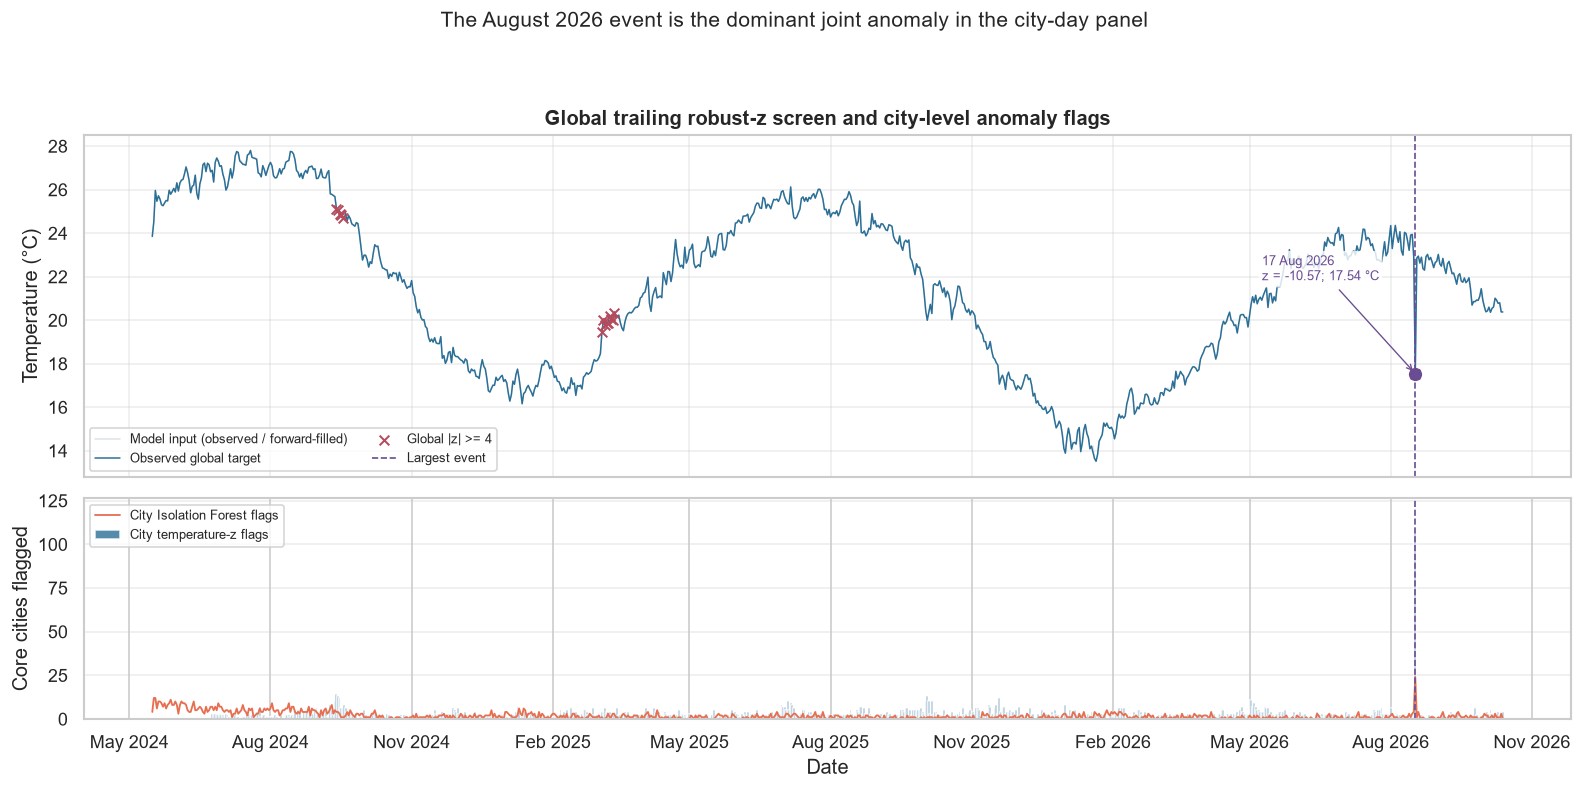

fig_16_global_and_city_anomalies.png


In [6]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(13.4, 6.6),
    sharex=True,
    gridspec_kw={"height_ratios": [1.55, 1.0]},
)

ax = axes[0]
ax.plot(
    frame.index,
    frame["target"],
    color="#DEE2E6",
    linewidth=0.9,
    label="Model input (observed / forward-filled)",
)
ax.plot(
    global_anomalies.index,
    global_anomalies["target"],
    color="#2A6F97",
    linewidth=0.9,
    label="Observed global target",
)
mask = global_anomalies["anomaly"]
ax.scatter(
    global_anomalies.index[mask],
    global_anomalies.loc[mask, "target"],
    color="#B44C5E",
    marker="x",
    s=34,
    linewidths=1.2,
    label="Global |z| >= 4",
    zorder=4,
)
ax.axvline(event_date, color="#6A4C93", linestyle="--", linewidth=1.0, label="Largest event")
ax.scatter(
    [event_date],
    [event_temp],
    color="#6A4C93",
    s=48,
    zorder=5,
)
ax.annotate(
    f"{event_date:%d %b %Y}\nz = {event_z:.2f}; {event_temp:.2f} °C",
    xy=(event_date, event_temp),
    xytext=(-92, 56),
    textcoords="offset points",
    fontsize=8,
    color="#6A4C93",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "none", "alpha": 0.82},
    arrowprops={"arrowstyle": "->", "color": "#6A4C93", "linewidth": 0.8},
)
ax.set_ylabel("Temperature (°C)")
ax.set_title("Global trailing robust-z screen and city-level anomaly flags")
ax.grid(alpha=0.35)
ax.legend(fontsize=7.5, ncol=2, loc="lower left", frameon=True)

ax = axes[1]
ax.bar(
    daily_counts["date_local"],
    daily_counts["temp_flags"],
    width=1.25,
    color="#2A6F97",
    alpha=0.80,
    label="City temperature-z flags",
)
ax.plot(
    daily_counts["date_local"],
    daily_counts["if_flags"],
    color="#E76F51",
    linewidth=1.1,
    label="City Isolation Forest flags",
)
ax.axvline(event_date, color="#6A4C93", linestyle="--", linewidth=1.0)
ax.set_xlabel("Date")
ax.set_ylabel("Core cities flagged")
ax.set_ylim(0, max(daily_counts["temp_flags"].max(), daily_counts["if_flags"].max()) * 1.18)
ax.grid(axis="y", alpha=0.35)
ax.legend(fontsize=7.5, loc="upper left", frameon=True)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(
    "The August 2026 event is the dominant joint anomaly in the city-day panel",
    fontsize=12.5,
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
path = save_figure(fig, "fig_16_global_and_city_anomalies.png")
plt.show()
print(path.name)

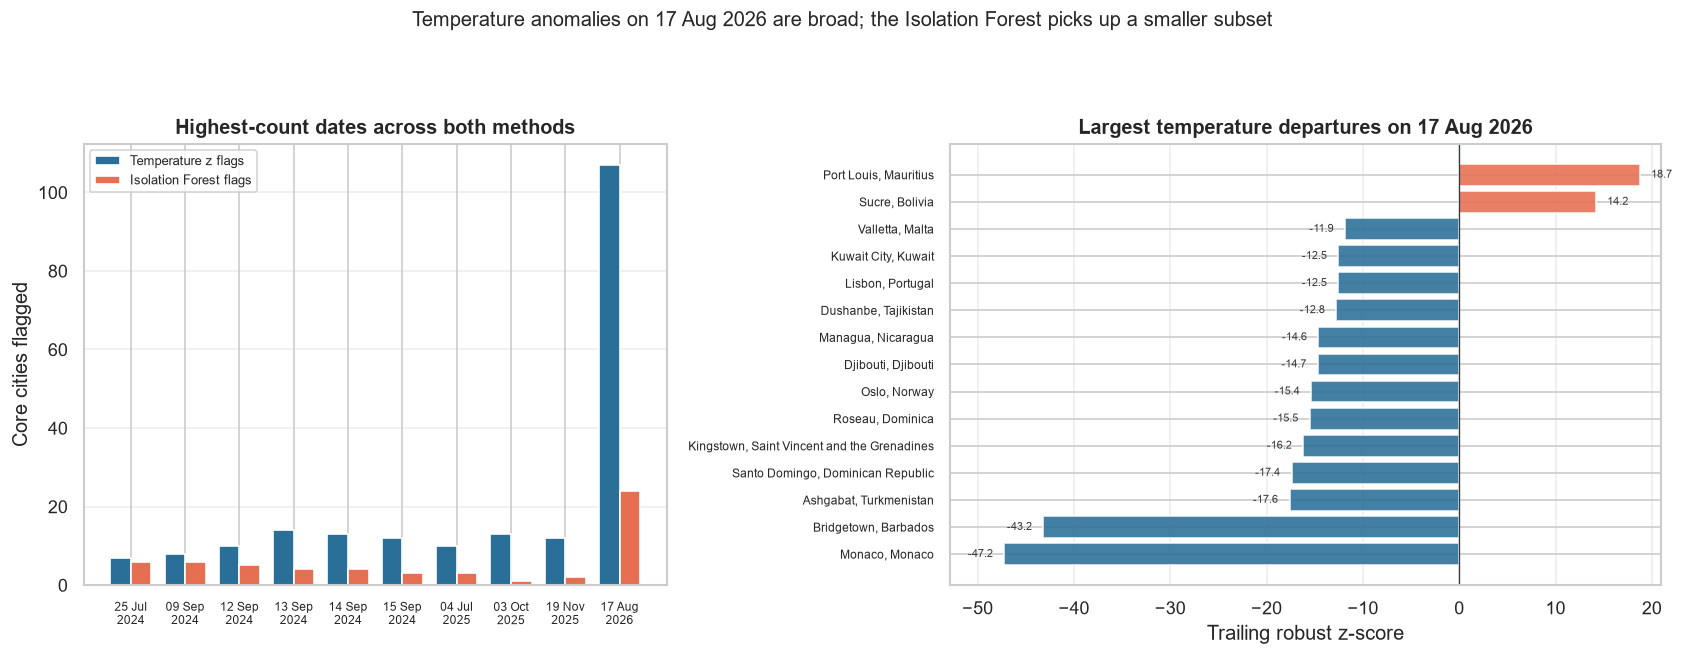

fig_17_anomaly_dates_and_event.png


In [7]:
plot_dates = (
    daily_counts.sort_values("either_flags", ascending=False)
    .head(10)
    .sort_values("date_local")
)
x = np.arange(len(plot_dates))
width = 0.38

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14.2, 5.4),
    gridspec_kw={"width_ratios": [1.0, 1.22]},
)

ax = axes[0]
ax.bar(
    x - width / 2,
    plot_dates["temp_flags"],
    width=width,
    color="#2A6F97",
    label="Temperature z flags",
)
ax.bar(
    x + width / 2,
    plot_dates["if_flags"],
    width=width,
    color="#E76F51",
    label="Isolation Forest flags",
)
ax.set_xticks(
    x,
    [date.strftime("%d %b\n%Y") for date in plot_dates["date_local"]],
    fontsize=7,
)
ax.set_ylabel("Core cities flagged")
ax.set_title("Highest-count dates across both methods")
ax.grid(axis="y", alpha=0.35)
ax.legend(fontsize=7.5, frameon=True)

event_cities = (
    event_flags.assign(abs_temp_z=lambda d: d["temp_z"].abs())
    .sort_values("abs_temp_z", ascending=False)
    .head(15)
    .sort_values("temp_z")
)
y = np.arange(len(event_cities))
colors = np.where(event_cities["temp_z"] < 0, "#2A6F97", "#E76F51")
ax = axes[1]
ax.barh(y, event_cities["temp_z"], color=colors, alpha=0.88)
ax.axvline(0, color="#343A40", linewidth=0.8)
ax.set_yticks(
    y,
    [f"{city}, {country}" for city, country in zip(event_cities["city"], event_cities["country"])],
    fontsize=7.0,
)
ax.set_xlabel("Trailing robust z-score")
ax.set_title(f"Largest temperature departures on {event_date:%d %b %Y}")
ax.grid(axis="x", alpha=0.35)
for ypos, value in enumerate(event_cities["temp_z"]):
    offset = 1.2 if value >= 0 else -1.2
    ax.text(
        value + offset,
        ypos,
        f"{value:.1f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=6.5,
        color="#343A40",
    )
ax.set_xlim(event_cities["temp_z"].min() * 1.12, event_cities["temp_z"].max() * 1.12)

fig.suptitle(
    "Temperature anomalies on 17 Aug 2026 are broad; the Isolation Forest picks up a smaller subset",
    fontsize=12.0,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_17_anomaly_dates_and_event.png")
plt.show()
print(path.name)

### Anomaly findings

- The global trailing robust-z screen selects **2026-08-17** as the largest
  departure: **z = −10.57**, with a global mean of **17.54 °C** against a
  prior-31-day median of **23.50 °C**. This is consistent with the Phase D
  data-quality note.
- On that date, **107 of 182** core cities are flagged by the temperature
  screen and **24** by the Isolation Forest; **17** are flagged by both, and
  **114** by at least one. The next-highest combined date has only **17**
  city-day flags, so the August event is an order of magnitude broader.
- Across the full panel, the methods agree on **94** city-days. The temperature
  screen contributes **2,125** unique flags and the Isolation Forest
  **1,506**. They are complementary rather than redundant.
- The Isolation Forest also has a cluster of high-count dates in **May 2024**,
  near the start of the record. Those flags are descriptive; without independent
  evidence they should not be called data errors.
- No anomaly was removed or corrected. The August event remains in fold 5 of the
  forecast backtest, so its effect on the reported errors is visible rather than
  hidden.

## 3. Extended forecast models and ensembles

All extended models use the same target, the same 15 lag/Fourier features, the
same recursive forecast rule, and the same six folds as Phase D.

- **ElasticNet + Fourier:** `StandardScaler` followed by `ElasticNetCV` with
  `l1_ratio=0.5` and a small alpha grid. Alpha is selected with a three-split
  chronological inner validation inside each outer training fold. The outer test
  window is never passed to the selector, and the scaler is fitted on training
  rows only.
- **HistGradientBoosting:** `max_iter=200`, `learning_rate=0.05`,
  `max_leaf_nodes=15`, `random_state=42` on the same feature set. It is a
  nonlinear, tree-based alternative to the linear models.
- **Ridge + ElasticNet mean:** equal-weight average of the two linear
  predictions. No weight is fitted on the test data.
- **All-model mean:** equal-weight average of Ridge, SARIMAX, ElasticNet, and
  HistGradientBoosting. It intentionally gives the weaker models the same vote
  as the stronger ones.
- **All-model median:** median of those four predictions, a robust alternative
  to the mean.

The ensembles are fixed combination rules, not meta-models trained on the test
window. That keeps the evaluation leakage-free, but it also means the ensemble
does not learn which base model is better.

In [8]:
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    advanced_predictions, folds = run_advanced_backtest(frame)
elapsed = time.perf_counter() - t0

if caught:
    print("Warnings captured during the advanced backtest:")
    for warning in caught:
        print(f"- {type(warning.message).__name__}: {warning.message}")
    raise RuntimeError("Unexpected warnings during the advanced backtest.")

model_counts = advanced_predictions.groupby("model").size()
assert len(model_counts) == 9, "Expected four base models, two extended models, and three ensembles."
assert model_counts.eq(180).all(), "Every model should have 180 test predictions."
assert advanced_predictions["fold"].nunique() == 6, "Expected six folds."
assert advanced_predictions.groupby("fold").size().eq(270).all(), "Each fold should contain 9 models x 30 days."
assert bool(advanced_predictions["observed"].all()), "Every test target should be observed."
first_train_index, first_test_index = folds[0]
assert first_train_index.max() < first_test_index.min(), "Training must precede testing."
assert len(first_train_index.intersection(first_test_index)) == 0, "Train/test overlap found."
print("Fold 1 boundary checks: training ends before test; zero date overlap; all test targets observed.")

print(f"Advanced backtest runtime: {elapsed:.1f} seconds")
print(f"Prediction rows: {len(advanced_predictions):,}")
print(f"Models / ensembles: {advanced_predictions['model'].nunique()}")
print(f"Rows per model: {model_counts.to_dict()}")
selected_alphas = (
    advanced_predictions.loc[
        advanced_predictions["model"].eq("elastic_net"), "alpha"
    ]
    .dropna()
    .unique()
)
print(f"ElasticNet alpha selected on inner validation: {selected_alphas.tolist()}")
print("SARIMAX convergence: 6/6 folds (the base backtest raises if a fit fails).")
display(advanced_predictions.head(8))

Fold 1 boundary checks: training ends before test; zero date overlap; all test targets observed.
Advanced backtest runtime: 21.3 seconds
Prediction rows: 1,620
Models / ensembles: 9
Rows per model: {'elastic_net': 180, 'ensemble_all_equal': 180, 'ensemble_all_median': 180, 'ensemble_ridge_enet': 180, 'hist_gradient_boosting': 180, 'persistence': 180, 'ridge_fourier': 180, 'sarimax_fourier': 180, 'seasonal_naive': 180}
ElasticNet alpha selected on inner validation: [0.01]
SARIMAX convergence: 6/6 folds (the base backtest raises if a fit fails).


,fold,origin,date,horizon,actual,model,prediction,observed,alpha
0,1,2026-04-16,2026-04-17,1,20.175275,persistence,19.934426,True,NaN
1,1,2026-04-16,2026-04-18,2,20.363736,persistence,19.934426,True,NaN
2,1,2026-04-16,2026-04-19,3,19.999454,persistence,19.934426,True,NaN
3,1,2026-04-16,2026-04-20,4,19.938251,persistence,19.934426,True,NaN
4,1,2026-04-16,2026-04-21,5,19.743716,persistence,19.934426,True,NaN
5,1,2026-04-16,2026-04-22,6,19.780328,persistence,19.934426,True,NaN
6,1,2026-04-16,2026-04-23,7,19.407650,persistence,19.934426,True,NaN
7,1,2026-04-16,2026-04-24,8,19.851099,persistence,19.934426,True,NaN


### Aggregate model comparison

MAE and RMSE are in **°C**; MAPE and sMAPE are percentages. All metrics use only
observed targets from the six test windows.

In [9]:
model_summary = summarize_model_metrics(advanced_predictions)
model_summary["model_label"] = model_summary["model"].map(MODEL_LABELS)

display_table = model_summary[
    ["model_label", "n", "mae", "rmse", "mape_pct", "smape_pct"]
].copy()
display_table.columns = [
    "Model",
    "Predictions",
    "MAE (°C)",
    "RMSE (°C)",
    "MAPE (%)",
    "sMAPE (%)",
]
display(
    display_table.round(
        {"MAE (°C)": 4, "RMSE (°C)": 4, "MAPE (%)": 3, "sMAPE (%)": 3}
    )
)

best_row = model_summary.iloc[0]
best_model = str(best_row["model"])
best_label = MODEL_LABELS[best_model]
ridge_row = model_summary.loc[model_summary["model"].eq("ridge_fourier")].iloc[0]
enet_row = model_summary.loc[model_summary["model"].eq("elastic_net")].iloc[0]
hgb_row = model_summary.loc[model_summary["model"].eq("hist_gradient_boosting")].iloc[0]
sarma_row = model_summary.loc[model_summary["model"].eq("sarimax_fourier")].iloc[0]
persistence_row = model_summary.loc[model_summary["model"].eq("persistence")].iloc[0]
seasonal_row = model_summary.loc[model_summary["model"].eq("seasonal_naive")].iloc[0]
ensemble_ridge_enet_row = model_summary.loc[model_summary["model"].eq("ensemble_ridge_enet")].iloc[0]
ensemble_equal_row = model_summary.loc[model_summary["model"].eq("ensemble_all_equal")].iloc[0]
ensemble_median_row = model_summary.loc[model_summary["model"].eq("ensemble_all_median")].iloc[0]

improvement_vs_persistence = 100.0 * (persistence_row["mae"] - best_row["mae"]) / persistence_row["mae"]
improvement_vs_ridge = 100.0 * (ridge_row["mae"] - best_row["mae"]) / ridge_row["mae"]

print(
    f"Lowest aggregate MAE: {best_label} — {best_row['mae']:.4f} °C "
    f"(RMSE {best_row['rmse']:.4f} °C; MAPE {best_row['mape_pct']:.3f}%; "
    f"sMAPE {best_row['smape_pct']:.3f}%)"
)
print(
    f"{best_label} is {improvement_vs_persistence:.1f}% lower in MAE than persistence "
    f"and {improvement_vs_ridge:.1f}% lower than Ridge + Fourier."
)
print(
    f"Ridge + ElasticNet mean: MAE {ensemble_ridge_enet_row['mae']:.4f} °C; "
    f"all-model mean: {ensemble_equal_row['mae']:.4f} °C; "
    f"all-model median: {ensemble_median_row['mae']:.4f} °C."
)
print(
    f"HistGradientBoosting: MAE {hgb_row['mae']:.4f} °C; "
    f"SARIMAX: {sarma_row['mae']:.4f} °C; "
    f"seasonal naive: {seasonal_row['mae']:.4f} °C."
)

,Model,Predictions,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%)
0,ElasticNet + Fourier,180,0.4705,0.7232,2.156,2.105
1,Ridge + ElasticNet mean,180,0.4812,0.7294,2.209,2.158
2,Ridge + Fourier,180,0.5012,0.7463,2.303,2.251
3,All-model mean,180,0.5474,0.7788,2.502,2.443
4,All-model median,180,0.5485,0.7923,2.508,2.445
5,HistGradientBoosting,180,0.7449,0.9782,3.362,3.331
6,SARIMAX + Fourier,180,0.9580,1.1936,4.354,4.210
7,Persistence,180,1.0368,1.2494,4.678,4.677
8,Seasonal naive,180,1.8513,2.0141,8.413,8.004


Lowest aggregate MAE: ElasticNet + Fourier — 0.4705 °C (RMSE 0.7232 °C; MAPE 2.156%; sMAPE 2.105%)
ElasticNet + Fourier is 54.6% lower in MAE than persistence and 6.1% lower than Ridge + Fourier.
Ridge + ElasticNet mean: MAE 0.4812 °C; all-model mean: 0.5474 °C; all-model median: 0.5485 °C.
HistGradientBoosting: MAE 0.7449 °C; SARIMAX: 0.9580 °C; seasonal naive: 1.8513 °C.


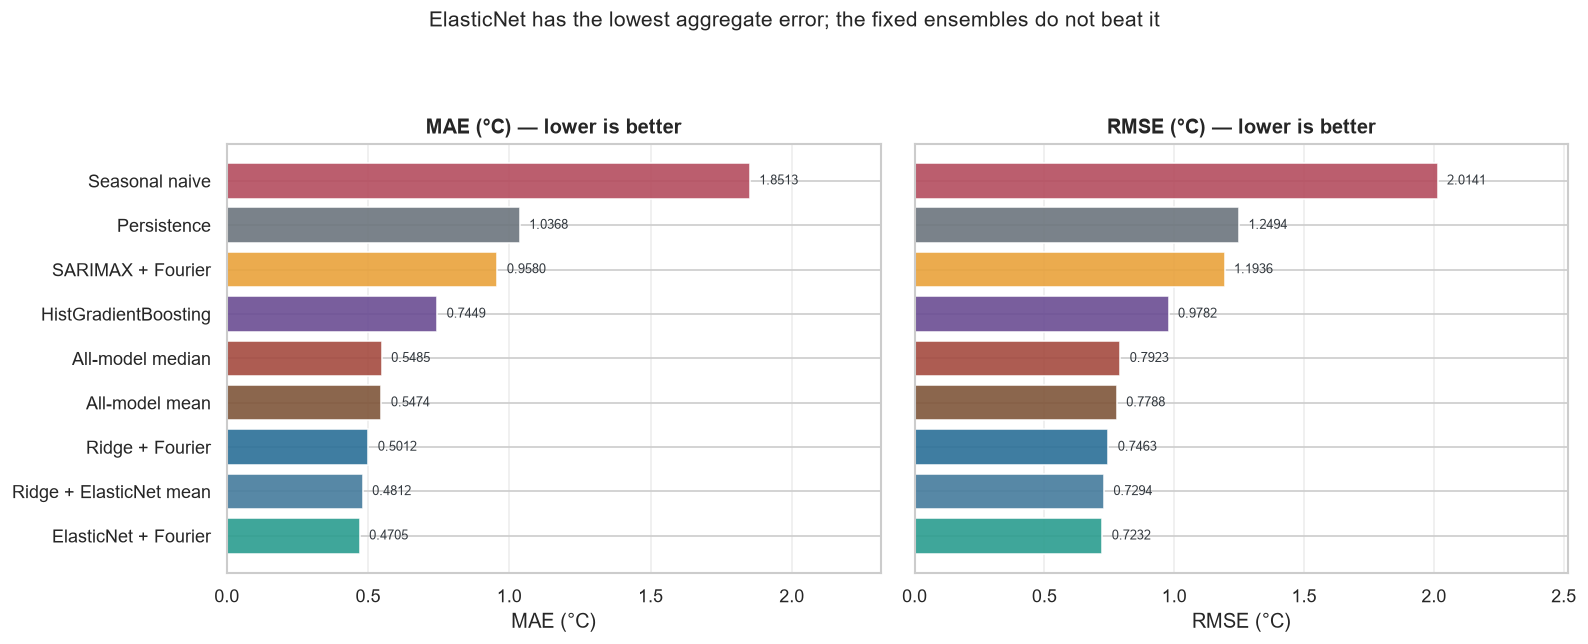

fig_18_advanced_model_comparison.png


In [10]:
ordered = model_summary.sort_values("mae").reset_index(drop=True)
labels = ordered["model_label"].tolist()
colors = ordered["model"].map(MODEL_COLORS).tolist()
y = np.arange(len(ordered))

fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.3), sharey=True)
for ax, metric, title, fmt in [
    (axes[0], "mae", "MAE (°C)", ".4f"),
    (axes[1], "rmse", "RMSE (°C)", ".4f"),
]:
    values = ordered[metric].to_numpy()
    ax.barh(y, values, color=colors, alpha=0.90)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel(title)
    ax.set_title(title + " — lower is better")
    for ypos, value in enumerate(values):
        ax.text(
            value + values.max() * 0.018,
            ypos,
            format(value, fmt),
            va="center",
            fontsize=7.5,
            color="#343A40",
        )
    ax.set_xlim(0, values.max() * 1.25)
    ax.grid(axis="x", alpha=0.35)

fig.suptitle(
    "ElasticNet has the lowest aggregate error; the fixed ensembles do not beat it",
    fontsize=12.5,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_18_advanced_model_comparison.png")
plt.show()
print(path.name)

### Per-fold stability

Aggregate metrics can hide instability. The per-fold MAE table shows whether
the extended model's advantage is broad or driven by one window. The all-model
mean wins one fold; no single model dominates every fold.

In [11]:
fold_metrics = per_fold_metrics(advanced_predictions)
fold_mae = fold_metrics.pivot(index="fold", columns="model", values="mae")[MODEL_ORDER]
fold_mae_labeled = fold_mae.rename(columns=MODEL_LABELS)

display(fold_mae_labeled.round(3))
fold_wins = fold_mae.idxmin(axis=1).map(MODEL_LABELS).value_counts()
fold_wins_best = int(fold_mae.idxmin(axis=1).eq(best_model).sum())
print("Per-fold MAE winners:")
print(fold_wins.to_string())
print(f"\n{best_label} wins {fold_wins_best} of {len(folds)} folds.")

model,Persistence,Seasonal naive,SARIMAX + Fourier,Ridge + Fourier,ElasticNet + Fourier,HistGradientBoosting,Ridge + ElasticNet mean,All-model mean,All-model median
fold,,,,,,,,,
1,0.655,2.335,1.269,0.624,0.434,0.550,0.526,0.495,0.526
2,1.609,1.868,0.665,0.570,0.480,0.781,0.516,0.523,0.521
3,1.066,1.940,0.793,0.496,0.541,0.697,0.516,0.477,0.536
4,0.717,1.930,1.328,0.570,0.592,1.031,0.575,0.748,0.739
5,1.463,1.904,1.349,0.449,0.490,0.911,0.462,0.747,0.674
6,0.711,1.131,0.345,0.298,0.286,0.499,0.291,0.295,0.295


Per-fold MAE winners:
ElasticNet + Fourier    3
Ridge + Fourier         2
All-model mean          1

ElasticNet + Fourier wins 3 of 6 folds.


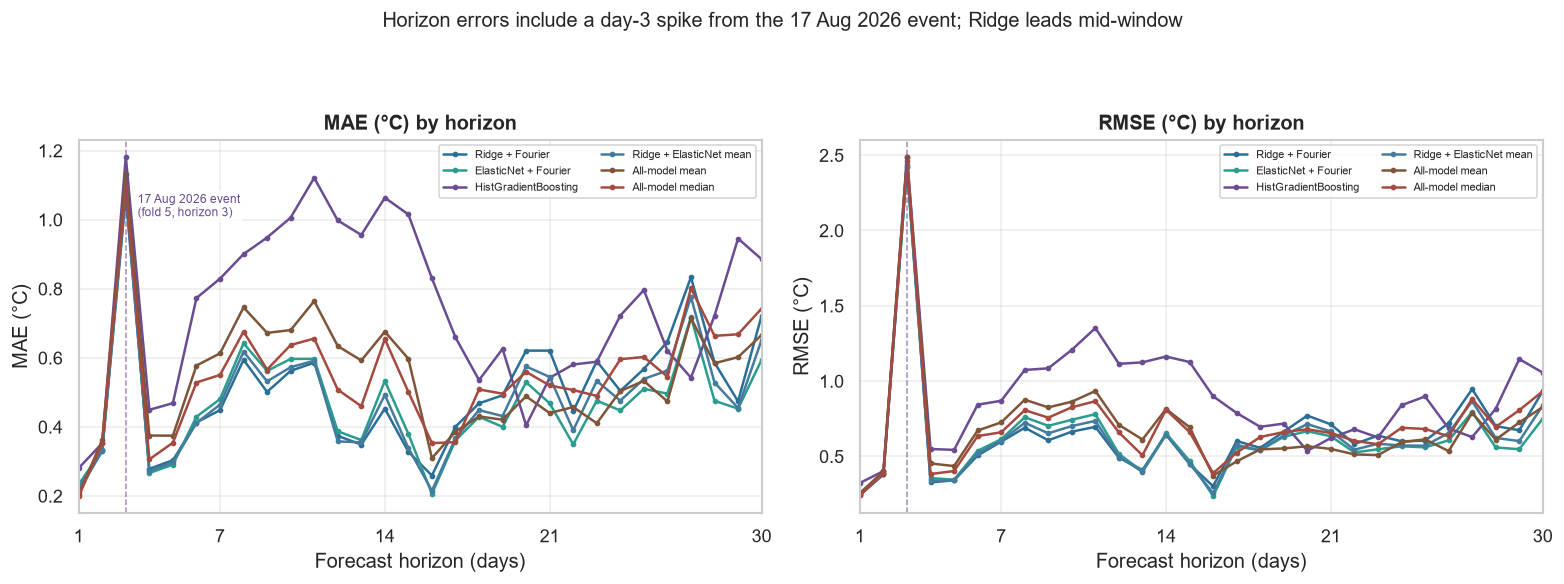

fig_19_advanced_error_by_horizon.png


In [12]:
horizon = horizon_metrics(advanced_predictions)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), sharex=True)
for ax, metric, title in [
    (axes[0], "mae", "MAE (°C)"),
    (axes[1], "rmse", "RMSE (°C)"),
]:
    for model in SELECTED_HORIZON_MODELS:
        subset = horizon.loc[horizon["model"].eq(model)].sort_values("horizon")
        ax.plot(
            subset["horizon"],
            subset[metric],
            color=MODEL_COLORS[model],
            linewidth=1.5,
            marker="o",
            markersize=2.4,
            label=MODEL_LABELS[model],
        )
    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel(title)
    ax.set_title(title + " by horizon")
    ax.set_xticks([1, 7, 14, 21, 30])
    ax.set_xlim(1, 30)
    ax.grid(alpha=0.35)
    ax.legend(fontsize=6.8, ncol=2, frameon=True)
    ax.axvline(3, color="#6A4C93", linestyle="--", linewidth=0.9, alpha=0.65)

axes[0].text(
    3.5,
    axes[0].get_ylim()[1] * 0.82,
    "17 Aug 2026 event\n(fold 5, horizon 3)",
    fontsize=7,
    color="#6A4C93",
    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.82},
)

fig.suptitle(
    "Horizon errors include a day-3 spike from the 17 Aug 2026 event; Ridge leads mid-window",
    fontsize=12.2,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
path = save_figure(fig, "fig_19_advanced_error_by_horizon.png")
plt.show()
print(path.name)

### Model-comparison findings

- **ElasticNet + Fourier** has the lowest aggregate MAE, **0.4705 °C**
  (RMSE **0.7232 °C**, MAPE **2.156%**, sMAPE **2.105%**). It is **6.1%** lower
  in MAE than Ridge + Fourier (0.5012 °C) and wins **3 of 6** folds.
- **Ridge + ElasticNet mean** reaches **0.4812 °C**. That beats Ridge alone but
  not ElasticNet. The all-model mean (**0.5474 °C**) and median
  (**0.5485 °C**) are weaker because they give equal weight to SARIMAX and
  HistGradientBoosting.
- **HistGradientBoosting** reaches **0.7449 °C**, worse than both linear models.
  Its recursive forecasts have no direct way to extrapolate beyond the target
  range seen in training, which is a plausible contributor; this is an
  interpretation, not a proven cause.
- **Per-fold stability:** ElasticNet wins folds 1, 2, and 6; Ridge wins folds 4
  and 5; the all-model mean wins fold 3. Fold 5 contains the August 2026 event
  and is the hardest window for the tree model.
- **Horizon profile:** the all-model median is best at day 1 (0.200 °C), Ridge
  is best at days 7 and 14 (0.449 and 0.453 °C), the all-model mean is best at
  day 21 (0.440 °C), and ElasticNet is best at day 30 (0.594 °C). There is no
  single winner at every horizon. The horizon figure's day-3 spike is the
  **2026-08-17 event** in fold 5, not a separate model failure; the event remains
  in the aggregate and per-fold results.
- **Last holdout:** ElasticNet is best (MAE **0.286 °C**), followed by the
  Ridge + ElasticNet mean (0.291 °C), the all-model median/mean (0.295 °C), and
  Ridge (0.298 °C). SARIMAX is 0.345 °C and HistGradientBoosting 0.499 °C.
- The ensemble evidence is honest: fixed equal-weight or median rules do **not**
  improve on the best single model here. Ensembling is not automatically
  beneficial when the base models differ substantially in accuracy.

## 4. Write the Phase E summary

The next cell writes `reports/advanced_summary.md` from the actual dataframes
produced above. The text is generated inside the notebook so the numbers cannot
drift from the executed results.

In [13]:
def markdown_table(dataframe: pd.DataFrame, digits: int = 3) -> str:
    columns = list(dataframe.columns)
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in dataframe.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                values.append(f"{np.round(value, digits):.{digits}f}")
            else:
                values.append(str(value))
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


event_row = daily_counts.loc[daily_counts["date_local"].eq(event_date)].iloc[0]
next_event_row = (
    daily_counts.sort_values("either_flags", ascending=False)
    .loc[lambda d: ~d["date_local"].eq(event_date)]
    .iloc[0]
)
event_flags = anomaly_flags.loc[anomaly_flags["date_local"].eq(event_date)].copy()
event_both = int(event_flags["both_flags"].sum())
event_top = (
    event_flags.assign(abs_temp_z=lambda d: d["temp_z"].abs())
    .sort_values("abs_temp_z", ascending=False)
    .iloc[0]
)

both_count = int(method_counts.loc[method_counts["category"].eq("Both methods"), "city_days"].iloc[0])
temp_only_count = int(
    method_counts.loc[
        method_counts["category"].eq("Temperature z only"), "city_days"
    ].iloc[0]
)
if_only_count = int(
    method_counts.loc[
        method_counts["category"].eq("Isolation Forest only"), "city_days"
    ].iloc[0]
)

global_top_md = global_top.head(10).copy()
global_top_md.columns = [
    "Date (UTC)",
    "Global mean (°C)",
    "Prior 31-day median (°C)",
    "Robust scale (°C)",
    "z",
    "Flagged",
]

method_md = method_counts.copy()
method_md.columns = ["Category", "City-days"]

combined_md = (
    daily_counts.sort_values("either_flags", ascending=False)
    .head(10)
    .copy()
)
combined_md["date_local"] = combined_md["date_local"].dt.strftime("%Y-%m-%d")
combined_md.columns = [
    "Date (local)",
    "Cities reporting",
    "Temperature z flags",
    "Isolation Forest flags",
    "Both",
    "Either",
]

event_city_md = (
    event_flags.assign(abs_temp_z=lambda d: d["temp_z"].abs())
    .sort_values("abs_temp_z", ascending=False)
    .head(10)
    [["country", "city", "temperature_celsius", "temp_z", "if_score", "temp_anomaly", "if_anomaly"]]
    .copy()
)
event_city_md.columns = [
    "Country",
    "City",
    "Temperature (°C)",
    "Temperature z",
    "IF score",
    "Temperature flag",
    "IF flag",
]

metric_md = model_summary[
    ["model_label", "n", "mae", "rmse", "mape_pct", "smape_pct"]
].copy()
metric_md.columns = [
    "Model",
    "Predictions",
    "MAE (°C)",
    "RMSE (°C)",
    "MAPE (%)",
    "sMAPE (%)",
]

fold_md = fold_mae_labeled.reset_index()
fold_md.columns = ["Fold"] + list(fold_md.columns[1:])

horizon_mae = (
    horizon_metrics(advanced_predictions)
    .pivot(index="horizon", columns="model", values="mae")
    [SELECTED_HORIZON_MODELS]
    .rename(columns=MODEL_LABELS)
)
horizon_md = horizon_mae.loc[[1, 7, 14, 21, 30]].reset_index()
horizon_md.columns = ["Horizon (days)"] + list(horizon_md.columns[1:])

last_fold = (
    per_fold_metrics(advanced_predictions.loc[advanced_predictions["fold"].eq(6)])
    .assign(model_label=lambda d: d["model"].map(MODEL_LABELS))
    .sort_values("mae")
)
last_fold_md = last_fold[["model_label", "mae", "rmse", "mape_pct", "smape_pct"]].copy()
last_fold_md.columns = ["Model", "MAE (°C)", "RMSE (°C)", "MAPE (%)", "sMAPE (%)"]

fold_win_text = "; ".join(
    f"{label}: {count}" for label, count in fold_wins.items()
)

summary_text = f"""# Phase E — Advanced anomaly detection and model comparison

**Status:** Complete for review. Phase E only. Climate/region analysis,
air-quality analysis, feature importance, and maps remain Phase F and are not
claimed here.

## Scope and inputs

- **Global target:** equal-weighted daily mean temperature across the 183 core
  locations (`temperature_celsius`).
- **Global calendar coverage:** {len(frame):,} daily dates from
  {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d};
  {int(frame["observed"].sum()):,} observed dates.
- **City-day panel:** {len(core):,} core city-days across
  {core.groupby(["country", "city"]).ngroups} cities.
- **Evaluation:** {len(folds)} chronological rolling-origin folds, each with a
  30-day test window; **{len(folds) * 30} predictions per model**.
- **Extended models:** ElasticNet + Fourier, HistGradientBoosting, and three
  fixed ensembles: Ridge + ElasticNet mean, all-model mean, all-model median.
- **Anomaly detection:** descriptive only; no anomaly is removed from the
  forecast evaluation.

## Anomaly detection

### Global temperature screen

The global screen uses a trailing 31-observed-day median and a
`1.4826 × MAD` scale; the current day is excluded from its own baseline. A day
is flagged when `|z| >= 4`. The observed global series has
**{int(global_anomalies["anomaly"].sum())}** flagged days out of
**{len(global_anomalies):,}**.

{markdown_table(global_top_md)}

**Largest event:** {event_date:%Y-%m-%d} has a global mean of
**{event_temp:.2f} °C**, versus a prior-31-day median of
**{event_median:.2f} °C**; **z = {event_z:.2f}** and the robust scale is
**{event_scale:.2f} °C**.

### City-day methods

The city temperature screen flags **{int(city_temperature["temp_anomaly"].sum()):,}**
of **{len(city_temperature):,}** city-days
(**{100 * city_temperature["temp_anomaly"].mean():.2f}%**). The Isolation Forest
(300 trees, 1% contamination) flags
**{int(city_multivariate["if_anomaly"].sum()):,}** city-days
(**{100 * city_multivariate["if_anomaly"].mean():.2f}%**). It is fitted on
within-city median/MAD-standardised temperature, humidity, pressure, wind,
cloud, precipitation, visibility, and UV features.

{markdown_table(method_md)}

The two detectors agree on **{both_count:,}** city-days. The temperature screen
contributes **{temp_only_count:,}** unique flags and the Isolation Forest
**{if_only_count:,}**. They answer different questions: a single-variable
temperature departure versus an unusual multivariate weather combination.

### The August 2026 event

On **{event_date:%Y-%m-%d}**, the temperature screen flags
**{int(event_row["temp_flags"])} of {int(event_row["n_cities"])}** core cities;
the Isolation Forest flags **{int(event_row["if_flags"])}**; **{event_both}**
are flagged by both and **{int(event_row["either_flags"])}** by at least one.
The next-highest combined date, **{next_event_row["date_local"]:%Y-%m-%d}**, has
only **{int(next_event_row["either_flags"])}** flags. The largest single
departure on the event date is **{event_top["city"]}, {event_top["country"]}**
at **{event_top["temperature_celsius"]:.1f} °C** with a temperature z-score of
**{event_top["temp_z"]:.2f}**.

{markdown_table(event_city_md)}

The event is broad and physically implausible as a one-day global temperature
change; the city pattern is dominated by extremely low readings in several
locations alongside a few high outliers. It is consistent with a source-data or
timestamp artefact. It is **not** removed from the backtest.

## Extended model comparison

### Setup

- Same 15 lag/Fourier features and recursive forecast rule as Phase D.
- ElasticNet: `StandardScaler` + `ElasticNetCV(l1_ratio=0.5, alphas=[0.01,
  0.03, 0.1, 0.3, 1.0])`, with a three-split chronological inner validation
  inside each outer training fold. Alpha was selected as 0.01 in all six
  folds; the outer test windows were not used for selection.
- HistGradientBoosting: `max_iter=200`, `learning_rate=0.05`,
  `max_leaf_nodes=15`, `random_state=42`.
- Ensembles are fixed combination rules, not meta-models fitted on the test
  windows.

### Aggregate metrics

{markdown_table(metric_md, digits=4)}

**Best aggregate model:** **{best_label}** with MAE **{best_row["mae"]:.4f} °C**,
RMSE **{best_row["rmse"]:.4f} °C**, MAPE **{best_row["mape_pct"]:.3f}%**, and
sMAPE **{best_row["smape_pct"]:.3f}%**. It is **{improvement_vs_persistence:.1f}%**
lower in MAE than persistence and **{improvement_vs_ridge:.1f}%** lower than
Ridge + Fourier.

**Ensembles:** Ridge + ElasticNet mean has MAE
**{ensemble_ridge_enet_row["mae"]:.4f} °C**; the all-model mean
**{ensemble_equal_row["mae"]:.4f} °C**; the all-model median
**{ensemble_median_row["mae"]:.4f} °C**. None beats ElasticNet. The Ridge +
ElasticNet mean beats Ridge alone but not ElasticNet.

### Per-fold MAE

{markdown_table(fold_md, digits=3)}

Per-fold winners: **{fold_win_text}**. ElasticNet wins
**{fold_wins_best} of {len(folds)}** folds; no model wins every fold.

### MAE at selected horizons

{markdown_table(horizon_md, digits=3)}

The all-model median is best at day 1 (0.200 °C), Ridge is best at days 7 and 14
(0.449 and 0.453 °C), the all-model mean is best at day 21 (0.440 °C), and
ElasticNet is best at day 30 (0.594 °C). The horizon figure includes a large
day-3 error spike from the 2026-08-17 event in fold 5; the event is retained in
the aggregate and per-fold results, and the selected horizon table follows the
Phase D checkpoints rather than removing the anomaly.

### Last holdout

Last test fold: **{folds[-1][1].min():%Y-%m-%d} to {folds[-1][1].max():%Y-%m-%d}**.

{markdown_table(last_fold_md, digits=3)}

## Findings

- **The August 2026 event is the dominant joint anomaly.** It is the largest
  global robust-z departure and the largest city-day cluster by a wide margin.
  It is best treated as a likely data-quality event, not a real one-day global
  temperature collapse.
- **The two anomaly methods are complementary.** Most flags are unique to one
  method. Agreement on {both_count:,} city-days identifies the strongest joint
  cases; disagreement is expected given the different inputs.
- **ElasticNet is the best aggregate forecaster in this extended comparison.**
  Its MAE of {best_row["mae"]:.4f} °C is lower than Ridge's
  {ridge_row["mae"]:.4f} °C, SARIMAX's {sarma_row["mae"]:.4f} °C, and
  HistGradientBoosting's {hgb_row["mae"]:.4f} °C.
- **Fixed ensembles do not beat the best single model.** Equal weighting gives
  too much influence to weaker base models. A learned stack would need an
  inner time-series validation design; it is not claimed here.
- **Horizon performance is not uniform.** Ridge is strongest at days 7 and 14,
  while ElasticNet is strongest at day 30. This is a reason to report the full
  horizon profile rather than only the aggregate.

## Leakage controls

- All models use the same six chronological folds; each training set ends one
  day before its test window.
- Base models are refitted inside each training fold. ElasticNet scaling is
  fitted on training rows only. No test target is used to fit a scaler, feature,
  or model.
- Recursive forecasts use prior predictions as history; actual test values are
  never inserted into the recursive path.
- Fourier terms are deterministic calendar features and do not use the target.
- The ensembles are fixed arithmetic combinations of base-model predictions;
  no ensemble weight is estimated on the test window.
- The six non-observed global dates are forward-filled only for model
  continuity; all are before the first test window and none is an evaluation
  target.
- Anomaly flags are descriptive and are never used to filter or reweight the
  forecast targets.

## Caveats

- The global target is an equal-weighted average of core locations, not a
  population- or area-weighted global temperature.
- The record spans a little over two years; it can describe seasonal behaviour
  in this panel but cannot establish a long-term climate trend.
- The anomaly thresholds are analytical choices, not ground truth. The
  Isolation Forest uses within-city standardisation over the full available
  history, so it is descriptive rather than a live real-time detector.
- The Isolation Forest's high-count May 2024 cluster is not confirmed as a data
  error. It may reflect unusual weather combinations near the start of the
  record or properties of the detector.
- The August 2026 event is retained in fold 5. That is deliberate: removing it
  after observing model scores would bias the evaluation.
- Model selection used the same six folds that are reported. The metrics are a
  model-selection estimate, not an untouched final holdout.
- HistGradientBoosting is weaker than the linear models in this recursive
  setup. The comparison is reported as observed; no post-hoc tuning was done on
  the test windows.
- Phase E does not include the final report, climate-region analysis,
  air-quality analysis, feature importance with two methods, or maps. Those are
  Phase F/G work.
- The official PM Accelerator mission statement is still a placeholder pending
  the user's exact text; it is not invented here.

## Figures

- `reports/figures/fig_16_global_and_city_anomalies.png`
- `reports/figures/fig_17_anomaly_dates_and_event.png`
- `reports/figures/fig_18_advanced_model_comparison.png`
- `reports/figures/fig_19_advanced_error_by_horizon.png`

## Phase E checkpoint

Phase E is complete for review. Stop here before Phase F (climate/region and
air-quality analysis, feature importance with at least two methods, and maps).
"""

report_path = REPORT_DIR / "advanced_summary.md"
report_path.write_text(summary_text, encoding="utf-8")
print(f"Wrote {report_path}")
print(f"Characters: {len(summary_text):,}")

Wrote D:\PMA\pma-data-analytics\reports\advanced_summary.md
Characters: 12,263


## Phase E checkpoint

Phase E is complete for review:

- `notebooks/04_advanced.ipynb` executed from top to bottom.
- `src/advanced.py` contains reusable anomaly-detection, extended-model, and
  ensemble functions.
- Four Phase E figures are saved in `reports/figures/`.
- `reports/advanced_summary.md` records the actual anomaly counts, model
  metrics, per-fold and horizon results, leakage controls, and caveats.
- No Phase F result is claimed yet.

Stop here for review before Phase F: climate/region analysis, air-quality
analysis, feature importance with at least two methods, and maps.

## 5. Phase F — Climate, region, air quality, feature importance, and maps

Phase E stopped at anomaly detection and forecast comparison. This section uses
the same 183-city core panel and the same six chronological folds, but the
questions are descriptive rather than forecast-scoring questions.

- **Climate-zone proxy:** absolute-latitude bands: Tropical (<23.5°),
  Subtropical (23.5–<35°), Temperate (35–<50°), High-latitude (≥50°). The
  source data has no official Köppen or climate-region field, so this rule is
  explicit and reproducible.
- **Region proxy:** the first component of the IANA timezone string
  (`Asia/...` → Asia, `America/...` → Americas). It is not an official
  continent classification and is used only for description.
- **Air quality:** the six pollutant columns have no documented concentration
  units in the source file. They are reported as **dataset units**, not as
  regulatory or health thresholds.
- **Maps:** a small public-domain Natural Earth 1:110m land layer provides
  geographic context. City values still come only from the weather panel.
- **Feature importance:** the forecast model's 15 lag/Fourier features are
  interpreted with two methods: standardised ElasticNet coefficients and
  permutation importance. The permutation is on one-step-ahead test rows, not
  the recursive 30-day backtest; this distinction is stated explicitly.

The broad **2026-08-17** temperature event remains in the panel. One day has a
negligible effect on multi-year city means, but it is not removed.

In [14]:
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch
from scipy.stats import kruskal, spearmanr

from src.eda import SHORT_LABELS
from src.advanced import (
    FEATURE_GROUPS,
    FEATURE_LABELS,
    feature_importance_tables,
    summarize_coefficients,
    summarize_feature_importance,
)
from src.regional import (
    CLIMATE_ZONE_COLORS,
    CLIMATE_ZONE_ORDER,
    calendar_zone_climate,
    city_climate_summary,
    city_month_pm25,
    correlation_summary,
    load_world_land,
    month_over_month_summary,
    monthly_zone_pm25,
    plot_world_land,
    pollutant_summary,
    region_summary,
    within_city_pm25_correlations,
    zone_summary,
)

print("Phase F helpers loaded.")

Phase F helpers loaded.


### 5.1 Climate and regional analysis

The city-level summary uses all core city-days and equal-weights cities rather
than city-days. Seasonal amplitude is the warmest monthly mean minus the
coolest monthly mean; it requires at least 12 usable calendar months and at
least 20 days per month. The zone tests are descriptive Kruskal-Wallis tests,
not causal estimates.

In [15]:
city_summary = city_climate_summary(core)
zone_table = zone_summary(city_summary)
region_table = region_summary(city_summary)

assert len(city_summary) == core.groupby(["country", "city"]).ngroups
assert city_summary["seasonal_amplitude_c"].notna().all(), (
    "Seasonal amplitude should be available for all core cities."
)

zone_temp_groups = [
    group["mean_temp_c"].dropna()
    for _, group in city_summary.groupby("climate_zone", observed=True)
]
zone_temp_h, zone_temp_p = kruskal(*zone_temp_groups)
zone_pm_groups = [
    group["median_pm25"].dropna()
    for _, group in city_summary.groupby("climate_zone", observed=True)
]
zone_pm_h, zone_pm_p = kruskal(*zone_pm_groups)
lat_temp_rho, lat_temp_p = spearmanr(
    city_summary["abs_latitude"], city_summary["mean_temp_c"]
)
lat_amp_rho, lat_amp_p = spearmanr(
    city_summary["abs_latitude"], city_summary["seasonal_amplitude_c"]
)

zone_display = zone_table.rename(
    columns={
        "climate_zone": "Climate zone",
        "n_cities": "Cities",
        "city_days": "City-days",
        "mean_temp_c": "Mean temp (°C)",
        "median_city_temp_c": "Median city temp (°C)",
        "seasonal_amplitude_median_c": "Median seasonal amplitude (°C)",
        "mean_humidity_pct": "Mean humidity (%)",
        "mean_uv_index": "Mean UV index",
        "mean_wind_kph": "Mean wind (kph)",
        "median_city_pm25": "Median city PM2.5",
        "pm25_q25": "PM2.5 Q1",
        "pm25_q75": "PM2.5 Q3",
    }
)
region_display = region_table.rename(
    columns={
        "region": "Region",
        "n_cities": "Cities",
        "city_days": "City-days",
        "mean_temp_c": "Mean temp (°C)",
        "seasonal_amplitude_median_c": "Median seasonal amplitude (°C)",
        "mean_humidity_pct": "Mean humidity (%)",
        "median_city_pm25": "Median city PM2.5",
    }
)

hottest = city_summary.loc[city_summary["mean_temp_c"].idxmax()]
coldest = city_summary.loc[city_summary["mean_temp_c"].idxmin()]
largest_amplitude = city_summary.loc[city_summary["seasonal_amplitude_c"].idxmax()]
smallest_amplitude = city_summary.loc[city_summary["seasonal_amplitude_c"].idxmin()]

print(
    f"Core cities summarized: {len(city_summary)} | "
    f"city-days with a temperature value: {int(city_summary['n_days'].sum()):,}"
)
print(
    f"Kruskal-Wallis across zones: temperature H={zone_temp_h:.2f}, "
    f"p={zone_temp_p:.3e}; PM2.5 H={zone_pm_h:.2f}, p={zone_pm_p:.3e}"
)
print(
    f"Absolute latitude vs city mean temperature: Spearman rho={lat_temp_rho:.3f}, "
    f"p={lat_temp_p:.3e}"
)
print(
    f"Absolute latitude vs seasonal amplitude: Spearman rho={lat_amp_rho:.3f}, "
    f"p={lat_amp_p:.3e}"
)
print(
    f"Hottest city mean: {hottest['city']}, {hottest['country']} "
    f"({hottest['mean_temp_c']:.2f} °C)"
)
print(
    f"Coldest city mean: {coldest['city']}, {coldest['country']} "
    f"({coldest['mean_temp_c']:.2f} °C)"
)
print(
    f"Largest seasonal amplitude: {largest_amplitude['city']}, "
    f"{largest_amplitude['country']} ({largest_amplitude['seasonal_amplitude_c']:.1f} °C)"
)
print(
    f"Smallest seasonal amplitude: {smallest_amplitude['city']}, "
    f"{smallest_amplitude['country']} ({smallest_amplitude['seasonal_amplitude_c']:.1f} °C)"
)
print()
display(zone_display.round(2))
print()
display(region_display.round(2))

Core cities summarized: 183 | city-days with a temperature value: 159,904
Kruskal-Wallis across zones: temperature H=99.01, p=2.538e-21; PM2.5 H=19.66, p=1.996e-04
Absolute latitude vs city mean temperature: Spearman rho=-0.733, p=4.200e-32
Absolute latitude vs seasonal amplitude: Spearman rho=0.816, p=5.162e-45
Hottest city mean: Doha, Qatar (32.97 °C)
Coldest city mean: Ulaanbaatar, Mongolia (6.04 °C)
Largest seasonal amplitude: Ulaanbaatar, Mongolia (45.1 °C)
Smallest seasonal amplitude: Majuro, Marshall Islands (2.0 °C)



,Climate zone,Cities,City-days,Mean temp (°C),Median city temp (°C),Median seasonal amplitude (°C),Mean humidity (%),Mean UV index,Mean wind (kph),Median city PM2.5,PM2.5 Q1,PM2.5 Q3
0,Tropical,90,78540,25.32,25.97,7.54,72.54,3.12,13.08,12.59,7.95,21.46
1,Subtropical,27,23646,23.99,23.36,20.94,52.17,4.65,13.14,24.35,13.82,46.72
2,Temperate,48,41950,16.75,17.28,30.21,61.36,2.63,11.21,12.80,10.46,16.21
3,High-latitude,18,15768,11.07,10.84,30.09,73.64,1.78,14.73,9.58,7.26,11.63


,Region,Cities,City-days,Mean temp (°C),Median seasonal amplitude (°C),Mean humidity (%),Median city PM2.5
0,Indian Ocean,5,4341,26.35,6.70,69.45,7.65
1,Pacific,11,9595,25.50,4.45,82.15,5.00
2,Asia,46,40243,24.73,22.21,50.66,20.72
3,Africa,43,37671,24.62,11.75,63.49,19.06
4,Atlantic,1,877,23.99,8.57,73.17,18.45
5,Americas,32,27766,20.86,6.55,83.96,8.88
6,Australia,1,874,15.21,24.49,62.74,5.18
7,Europe,44,38537,13.98,29.60,69.87,11.84


In [16]:
zone_climate = calendar_zone_climate(core, city_summary)
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_temp_table = (
    zone_climate.pivot(
        index="climate_zone",
        columns="month_name",
        values="mean_temp_c",
    )
    .reindex(columns=month_order)
)
print("Calendar-month mean temperature by derived climate zone (°C):")
display(monthly_temp_table.round(2))

Calendar-month mean temperature by derived climate zone (°C):


month_name,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
climate_zone,,,,,,,,,,,,
Tropical,24.51,24.84,25.23,25.69,26.17,25.90,25.05,24.94,25.46,25.59,25.26,24.85
Subtropical,18.14,19.19,20.82,23.22,25.60,27.05,27.07,27.23,26.51,24.87,22.08,19.21
Temperate,5.01,6.43,10.05,14.34,18.92,24.35,26.22,25.89,21.05,16.06,10.32,5.98
High-latitude,-1.55,-1.83,4.97,8.91,14.72,18.73,20.34,19.11,15.81,10.17,4.62,2.47


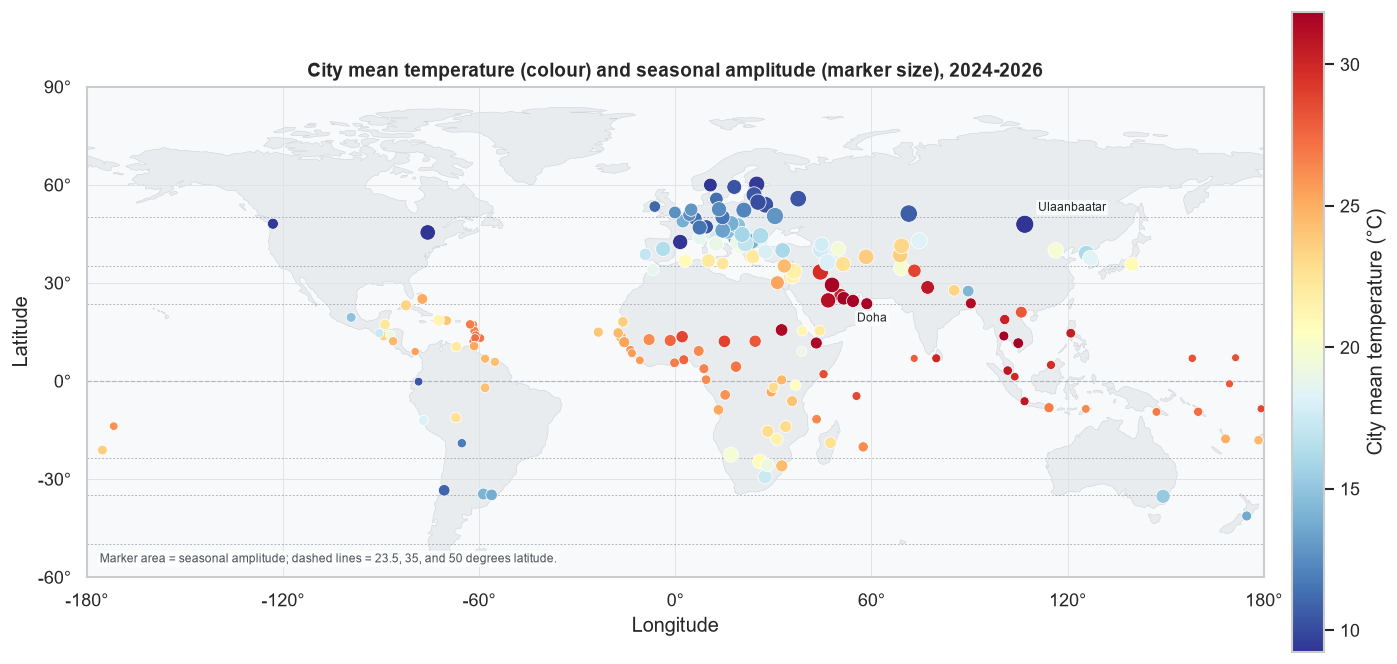

fig_20_climate_zone_map.png


In [17]:
land = load_world_land()
temperature_low, temperature_high = city_summary["mean_temp_c"].quantile([0.02, 0.98])
temperature_norm = Normalize(vmin=temperature_low, vmax=temperature_high)
marker_sizes = 18.0 + 2.2 * city_summary["seasonal_amplitude_c"].fillna(
    city_summary["seasonal_amplitude_c"].median()
)

fig, ax = plt.subplots(figsize=(12.8, 7.2))
plot_world_land(ax, land)
scatter = ax.scatter(
    city_summary["longitude"],
    city_summary["latitude"],
    c=city_summary["mean_temp_c"],
    cmap="RdYlBu_r",
    norm=temperature_norm,
    s=marker_sizes,
    edgecolors="white",
    linewidths=0.45,
    zorder=3,
)
colorbar = fig.colorbar(scatter, ax=ax, shrink=0.78, pad=0.02)
colorbar.set_label("City mean temperature (°C)")

for city_name, offset in {"Doha": (8, -14), "Ulaanbaatar": (8, 8)}.items():
    row = city_summary.loc[city_summary["city"].eq(city_name)].iloc[0]
    ax.annotate(
        city_name,
        xy=(row["longitude"], row["latitude"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=7.2,
        color="#212529",
        bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.8},
    )

ax.text(
    -176,
    -55.5,
    "Marker area = seasonal amplitude; dashed lines = 23.5, 35, and 50 degrees latitude.",
    fontsize=7.2,
    color="#495057",
    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.85},
)
ax.set_title(
    "City mean temperature (colour) and seasonal amplitude (marker size), 2024-2026",
    fontsize=11.5,
)
fig.tight_layout()
path = save_figure(fig, "fig_20_climate_zone_map.png")
plt.show()
print(path.name)

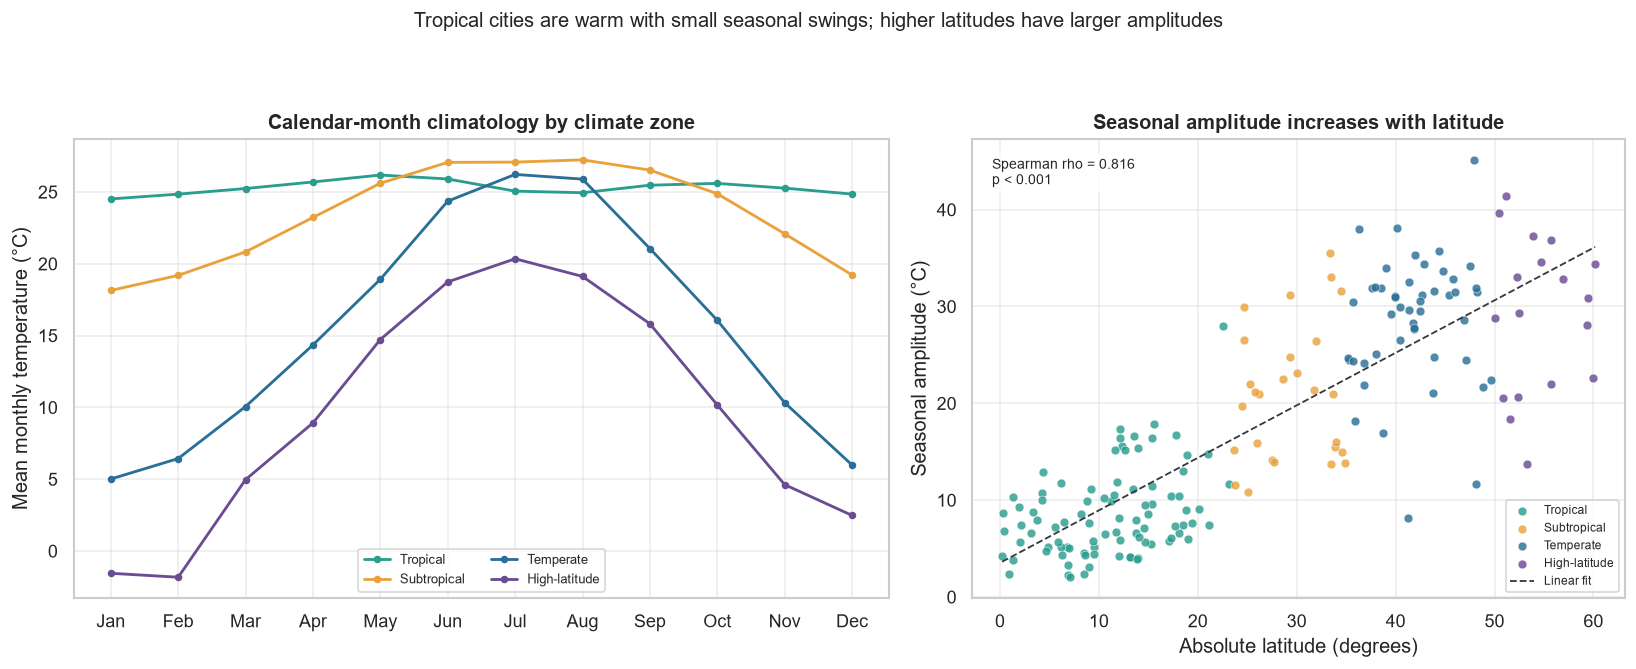

fig_21_climate_zone_profiles.png


In [18]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.8, 5.5),
    gridspec_kw={"width_ratios": [1.25, 1.0]},
)

ax = axes[0]
for zone in CLIMATE_ZONE_ORDER:
    subset = zone_climate.loc[zone_climate["climate_zone"].eq(zone)].sort_values("month_num")
    ax.plot(
        subset["month_num"],
        subset["mean_temp_c"],
        color=CLIMATE_ZONE_COLORS[zone],
        marker="o",
        markersize=3.5,
        linewidth=1.7,
        label=zone,
    )
ax.set_xticks(range(1, 13), month_order)
ax.set_ylabel("Mean monthly temperature (°C)")
ax.set_title("Calendar-month climatology by climate zone")
ax.grid(alpha=0.35)
ax.legend(fontsize=7.8, frameon=True, loc="lower center", ncol=2)

ax = axes[1]
for zone in CLIMATE_ZONE_ORDER:
    subset = city_summary.loc[city_summary["climate_zone"].eq(zone)]
    ax.scatter(
        subset["abs_latitude"],
        subset["seasonal_amplitude_c"],
        s=28,
        alpha=0.82,
        color=CLIMATE_ZONE_COLORS[zone],
        edgecolors="white",
        linewidths=0.35,
        label=zone,
    )
fit = np.polyfit(city_summary["abs_latitude"], city_summary["seasonal_amplitude_c"], 1)
fit_x = np.linspace(
    city_summary["abs_latitude"].min(),
    city_summary["abs_latitude"].max(),
    100,
)
ax.plot(fit_x, np.polyval(fit, fit_x), color="#343A40", linestyle="--", linewidth=1.1, label="Linear fit")
ax.set_xlabel("Absolute latitude (degrees)")
ax.set_ylabel("Seasonal amplitude (°C)")
ax.set_title("Seasonal amplitude increases with latitude")
ax.text(
    0.03,
    0.96,
    f"Spearman rho = {lat_amp_rho:.3f}\np < 0.001",
    transform=ax.transAxes,
    va="top",
    fontsize=8.5,
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "none", "alpha": 0.85},
)
ax.grid(alpha=0.35)
ax.legend(fontsize=7.2, frameon=True, loc="lower right")

fig.suptitle(
    "Tropical cities are warm with small seasonal swings; higher latitudes have larger amplitudes",
    fontsize=12,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
path = save_figure(fig, "fig_21_climate_zone_profiles.png")
plt.show()
print(path.name)

### 5.2 Air-quality analysis

PM2.5 is used as the primary pollutant indicator because it has complete
coverage in the core panel. The source does not document concentration units,
so all values remain in **dataset units**. No comparison with WHO, EPA, or
national regulatory thresholds is made.

Two questions are separated:

1. **Where and when are values high?** City medians and climate-zone monthly
   medians are descriptive.
2. **How does PM2.5 co-vary with local weather?** One Spearman correlation is
   computed per city, then summarised across cities. Pooling all city-days
   would mix cross-city climate differences with within-city behaviour.

In [19]:
pollutant_table = pollutant_summary(core)
city_month_pm = city_month_pm25(core)
pm25_step_table = month_over_month_summary(city_month_pm)
pm25_zone_month = monthly_zone_pm25(core, city_summary)

top_pm = city_summary.sort_values("median_pm25", ascending=False).head(8).copy()
bottom_pm = city_summary.sort_values("median_pm25").head(5).copy()

pollutant_display = pollutant_table.rename(
    columns={
        "pollutant": "Pollutant",
        "units": "Units",
        "n": "Rows",
        "missing": "Missing",
        "median": "Median",
        "mean": "Mean",
        "p95": "P95",
        "p99": "P99",
        "max": "Max",
    }
)
step_display = pm25_step_table.rename(
    columns={
        "month": "Month",
        "previous_month": "Previous month",
        "n_cities": "Cities",
        "median_ratio": "Median city ratio",
        "share_gt_1_5": "Share ratio >1.5",
        "share_gt_2": "Share ratio >2",
    }
)
top_pm_display = top_pm[
    ["country", "city", "climate_zone", "region", "median_pm25", "p95_pm25"]
].rename(
    columns={
        "country": "Country",
        "city": "City",
        "climate_zone": "Climate zone",
        "region": "Region",
        "median_pm25": "Median PM2.5",
        "p95_pm25": "P95 PM2.5",
    }
)

sep24 = pm25_step_table.loc[pm25_step_table["month"].eq("2024-09")].iloc[0]
sep25 = pm25_step_table.loc[pm25_step_table["month"].eq("2025-09")].iloc[0]
sep26 = pm25_step_table.loc[pm25_step_table["month"].eq("2026-09")].iloc[0]

print(
    f"PM2.5 in dataset units: median of city medians={city_summary['median_pm25'].median():.2f}; "
    f"pooled city-day median={pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'median'].iloc[0]:.2f}; "
    f"95th percentile of city-days={pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'p95'].iloc[0]:.2f}; "
    f"maximum city-day={pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'max'].iloc[0]:.2f}"
)
print(
    f"Sep 2024 vs Aug 2024: median city ratio={sep24['median_ratio']:.3f}; "
    f"{100 * sep24['share_gt_1_5']:.1f}% of cities >1.5x; "
    f"{100 * sep24['share_gt_2']:.1f}% >2x"
)
print(
    f"Same comparison in 2025: median ratio={sep25['median_ratio']:.3f}; "
    f"2026: {sep26['median_ratio']:.3f}"
)
print(
    f"Highest city median: {top_pm.iloc[0]['city']}, {top_pm.iloc[0]['country']} "
    f"({top_pm.iloc[0]['median_pm25']:.2f} dataset units)"
)
print(
    f"Lowest city median: {bottom_pm.iloc[0]['city']}, {bottom_pm.iloc[0]['country']} "
    f"({bottom_pm.iloc[0]['median_pm25']:.2f} dataset units)"
)
print()
display(pollutant_display.round(2))
print()
display(step_display.round(3))
print()
display(top_pm_display.round(2))

PM2.5 in dataset units: median of city medians=12.77; pooled city-day median=13.32; 95th percentile of city-days=74.37; maximum city-day=1614.10
Sep 2024 vs Aug 2024: median city ratio=2.932; 78.1% of cities >1.5x; 64.5% >2x
Same comparison in 2025: median ratio=0.972; 2026: 0.937
Highest city median: Riyadh, Saudi Arabia (99.99 dataset units)
Lowest city median: Honiara, Solomon Islands (2.40 dataset units)



,Pollutant,Units,Rows,Missing,Median,Mean,P95,P99,Max
0,PM2.5,dataset units,159905,0,13.32,23.08,74.37,154.29,1614.10
1,PM10,dataset units,159903,2,19.06,46.80,150.90,470.46,6037.29
2,Ozone,dataset units,159905,0,54.40,58.18,113.00,161.70,480.70
3,Nitrogen dioxide,dataset units,159905,0,5.73,14.38,60.44,109.89,427.70
4,Sulphur dioxide,dataset units,159904,1,2.35,9.95,48.10,109.52,521.33
5,Carbon monoxide,dataset units,159904,1,264.85,419.46,1118.72,2963.65,38879.40


,Month,Previous month,Cities,Median city ratio,Share ratio >1.5,Share ratio >2
0,2024-09,2024-08,183,2.932,0.781,0.645
1,2025-09,2025-08,183,0.972,0.049,0.000
2,2026-09,2026-08,183,0.937,0.049,0.016


,Country,City,Climate zone,Region,Median PM2.5,P95 PM2.5
112,Saudi Arabia,Riyadh,Subtropical,Asia,99.99,368.24
37,Indonesia,Jakarta,Tropical,Asia,99.34,301.14
127,China,Beijing,Temperate,Asia,95.65,286.34
99,India,New Delhi,Subtropical,Asia,91.01,216.96
103,Kuwait,Kuwait City,Subtropical,Asia,81.55,189.95
97,Chile,Santiago,Subtropical,Americas,60.50,597.29
93,Bahrain,Manama,Subtropical,Asia,58.09,119.03
86,Vietnam,Hanoi,Tropical,Asia,54.67,155.91


In [20]:
pm25_correlations = within_city_pm25_correlations(core)
pm25_corr_summary = correlation_summary(pm25_correlations)
pm25_corr_display = pm25_corr_summary.assign(
    variable=lambda frame: frame["variable"].map(SHORT_LABELS)
).rename(
    columns={
        "variable": "Weather variable",
        "n_cities": "Cities",
        "median_r": "Median rho",
        "q25_r": "Q1 rho",
        "q75_r": "Q3 rho",
        "share_negative": "Share negative",
        "share_positive": "Share positive",
        "share_significant_negative": "Share significant negative",
        "share_significant_positive": "Share significant positive",
    }
)

most_negative = pm25_corr_summary.sort_values("median_r").iloc[0]
most_positive = pm25_corr_summary.sort_values("median_r", ascending=False).iloc[0]
print(
    f"Most negative median association: {SHORT_LABELS[most_negative['variable']]} "
    f"(rho={most_negative['median_r']:.3f}, "
    f"{100 * most_negative['share_significant_negative']:.1f}% of cities significant negative)"
)
print(
    f"Most positive median association: {SHORT_LABELS[most_positive['variable']]} "
    f"(rho={most_positive['median_r']:.3f}, "
    f"{100 * most_positive['share_significant_positive']:.1f}% of cities significant positive)"
)
print()
display(pm25_corr_display.round(3))

Most negative median association: Wind (rho=-0.167, 63.9% of cities significant negative)
Most positive median association: Pressure (rho=0.139, 63.4% of cities significant positive)



,Weather variable,Cities,Median rho,Q1 rho,Q3 rho,Share negative,Share positive,Share significant negative,Share significant positive
0,Temp,183,-0.103,-0.260,0.124,0.617,0.383,0.546,0.311
1,Humidity,183,-0.045,-0.201,0.135,0.546,0.454,0.432,0.372
2,Wind,183,-0.167,-0.310,0.098,0.694,0.306,0.639,0.273
3,Pressure,183,0.139,-0.034,0.281,0.295,0.705,0.197,0.634
4,Precip,183,-0.146,-0.251,-0.070,0.885,0.115,0.754,0.049
5,Cloud,183,-0.107,-0.224,-0.020,0.781,0.219,0.596,0.098
6,UV,181,-0.063,-0.276,0.111,0.569,0.431,0.497,0.304
7,Visibility,172,-0.085,-0.219,0.030,0.680,0.320,0.535,0.157


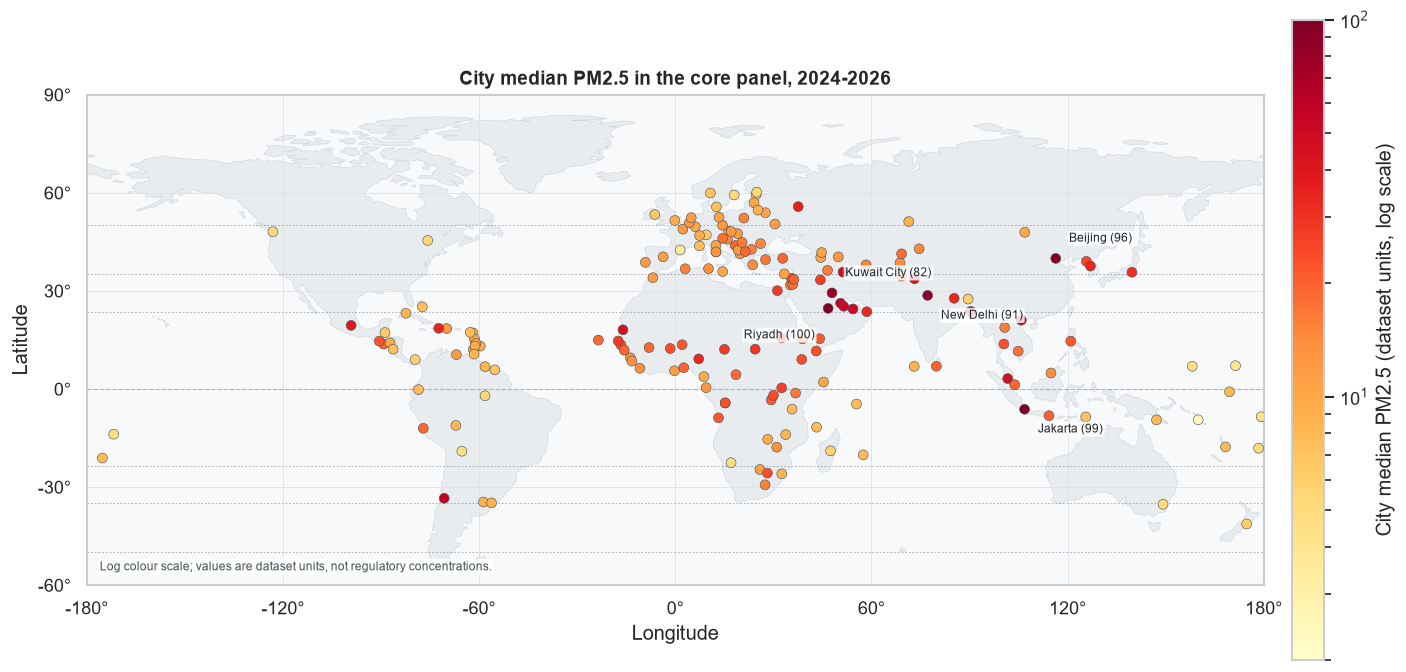

fig_22_pm25_city_map.png


In [21]:
fig, ax = plt.subplots(figsize=(12.8, 7.2))
plot_world_land(ax, land)
pm_norm = LogNorm(vmin=2.0, vmax=100.0)
scatter = ax.scatter(
    city_summary["longitude"],
    city_summary["latitude"],
    c=city_summary["median_pm25"],
    cmap="YlOrRd",
    norm=pm_norm,
    s=35,
    edgecolors="#495057",
    linewidths=0.35,
    zorder=3,
)
colorbar = fig.colorbar(scatter, ax=ax, shrink=0.78, pad=0.02)
colorbar.set_label("City median PM2.5 (dataset units, log scale)")

label_offsets = {
    "Riyadh": (-8, -18, "right"),
    "Jakarta": (8, -14, "left"),
    "Beijing": (8, 10, "left"),
    "New Delhi": (8, -14, "left"),
    "Kuwait City": (8, 10, "left"),
}
for _, row in top_pm.head(5).iterrows():
    dx, dy, horizontal = label_offsets.get(row["city"], (8, 8, "left"))
    ax.annotate(
        f"{row['city']} ({row['median_pm25']:.0f})",
        xy=(row["longitude"], row["latitude"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=7.0,
        color="#212529",
        ha=horizontal,
        bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.82},
    )

ax.text(
    -176,
    -55.5,
    "Log colour scale; values are dataset units, not regulatory concentrations.",
    fontsize=7.2,
    color="#495057",
    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.85},
)
ax.set_title("City median PM2.5 in the core panel, 2024-2026", fontsize=11.5)
fig.tight_layout()
path = save_figure(fig, "fig_22_pm25_city_map.png")
plt.show()
print(path.name)

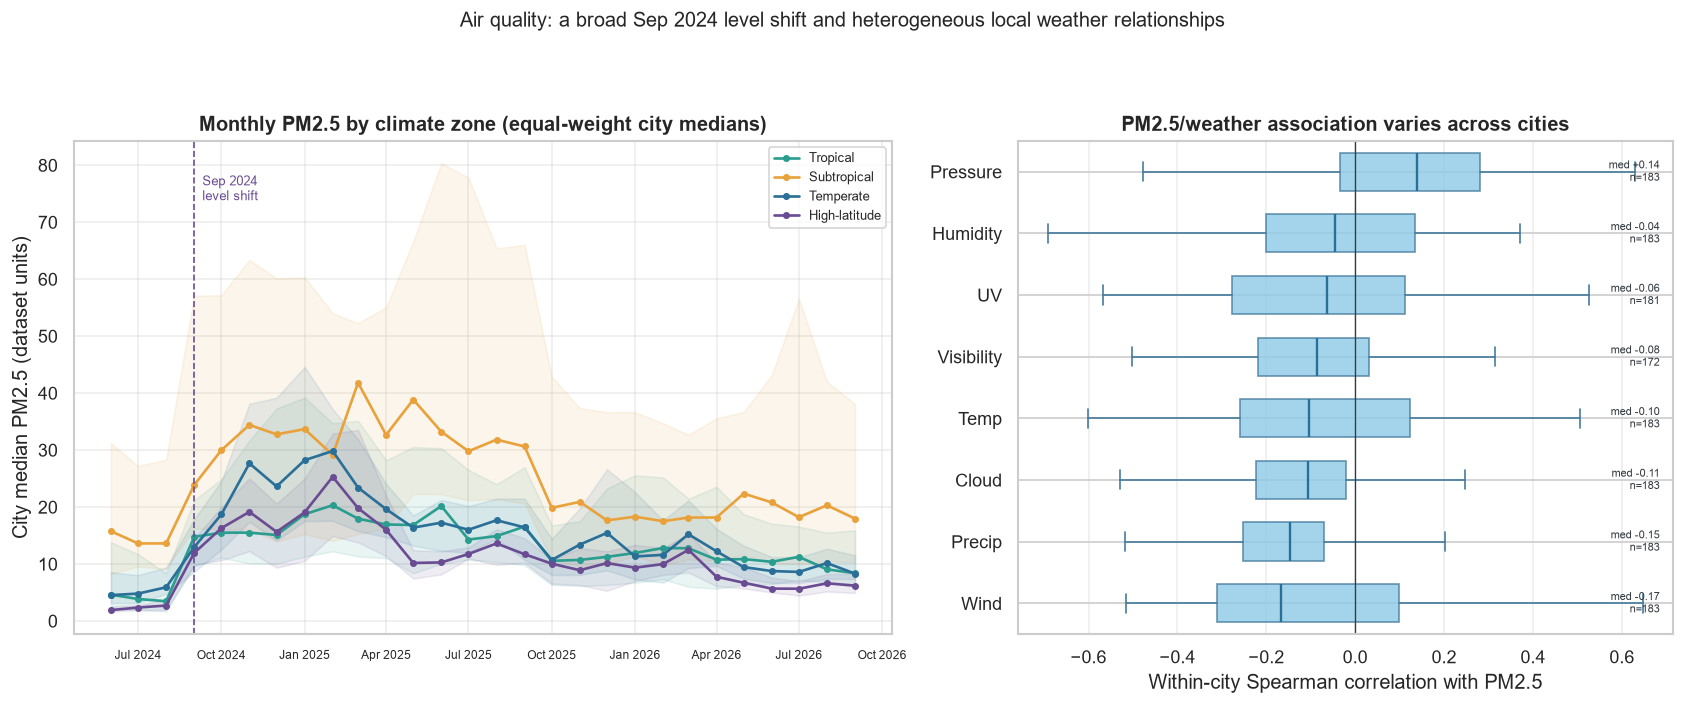

fig_23_air_quality_patterns.png


In [22]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14.2, 5.8),
    gridspec_kw={"width_ratios": [1.25, 1.0]},
)

ax = axes[0]
for zone in CLIMATE_ZONE_ORDER:
    subset = pm25_zone_month.loc[pm25_zone_month["climate_zone"].eq(zone)].sort_values("month_start")
    ax.plot(
        subset["month_start"],
        subset["pm25_median"],
        color=CLIMATE_ZONE_COLORS[zone],
        marker="o",
        markersize=3.2,
        linewidth=1.6,
        label=zone,
    )
    ax.fill_between(
        subset["month_start"],
        subset["pm25_q25"],
        subset["pm25_q75"],
        color=CLIMATE_ZONE_COLORS[zone],
        alpha=0.10,
    )
ax.axvline(pd.Timestamp("2024-09-01"), color="#6A4C93", linestyle="--", linewidth=1.0)
ax.text(
    pd.Timestamp("2024-09-10"),
    ax.get_ylim()[1] * 0.93,
    "Sep 2024\nlevel shift",
    fontsize=7.5,
    color="#6A4C93",
    va="top",
)
ax.set_ylabel("City median PM2.5 (dataset units)")
ax.set_title("Monthly PM2.5 by climate zone (equal-weight city medians)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.tick_params(axis="x", labelsize=7)
ax.grid(alpha=0.35)
ax.legend(fontsize=7.5, frameon=True)

ax = axes[1]
corr_order = pm25_corr_summary.sort_values("median_r")["variable"].tolist()
corr_labels = [SHORT_LABELS[column] for column in corr_order]
corr_data = [
    pm25_correlations.loc[pm25_correlations["variable"].eq(column), "rho"].to_numpy()
    for column in corr_order
]
positions = np.arange(len(corr_order))
ax.boxplot(
    corr_data,
    positions=positions,
    orientation="horizontal",
    widths=0.62,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "#2A6F97", "linewidth": 1.4},
    boxprops={"facecolor": "#8ECAE6", "edgecolor": "#457B9D", "alpha": 0.8},
    whiskerprops={"color": "#457B9D"},
    capprops={"color": "#457B9D"},
)
ax.set_yticks(positions, corr_labels)
ax.axvline(0, color="#343A40", linewidth=0.8)
ax.set_xlabel("Within-city Spearman correlation with PM2.5")
ax.set_ylabel("")
ax.set_title("PM2.5/weather association varies across cities")
for position, column in enumerate(corr_order):
    row = pm25_corr_summary.loc[pm25_corr_summary["variable"].eq(column)].iloc[0]
    ax.text(
        0.98,
        position,
        f"med {row['median_r']:+.2f}\nn={int(row['n_cities'])}",
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=6.8,
        color="#343A40",
    )
ax.grid(axis="x", alpha=0.35)

fig.suptitle(
    "Air quality: a broad Sep 2024 level shift and heterogeneous local weather relationships",
    fontsize=12,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
path = save_figure(fig, "fig_23_air_quality_patterns.png")
plt.show()
print(path.name)

### 5.3 Feature importance with two methods

The forecast design has 15 features: six annual Fourier terms, seven lag terms,
and two rolling means. Two independent interpretation methods are used:

1. **Standardised ElasticNet coefficients.** Each feature is scaled before the
   model, so coefficient magnitudes are comparable. The table reports the mean
   coefficient across the six training folds and its fold-to-fold standard
   deviation.
2. **Permutation importance.** A feature is randomly permuted on the
   one-step-ahead test rows, and the increase in MAE is recorded. This is
   repeated 20 times per fold for ElasticNet and HistGradientBoosting.
   A grouped version permutes each feature family together, which is less
   sensitive to collinearity among individual lags.

**Important distinction:** this permutation importance is for one-step-ahead
prediction with observed lags. It is not the recursive 30-day backtest metric.
In a recursive forecast, lag-1 is replaced by the model's own previous
prediction, so the relative importance of seasonal and long-lag terms can
differ. No recursive feature-importance claim is made here.

In [23]:
importance_start = time.perf_counter()
with warnings.catch_warnings(record=True) as importance_warnings:
    warnings.simplefilter("always")
    importance_tables = feature_importance_tables(frame, folds, n_repeats=20)
importance_elapsed = time.perf_counter() - importance_start

if importance_warnings:
    print("Warnings captured during feature-importance calculation:")
    for warning in importance_warnings:
        print(f"- {type(warning.message).__name__}: {warning.message}")
    raise RuntimeError("Unexpected warnings during feature-importance calculation.")

coef_summary = summarize_coefficients(importance_tables["coefficients"])
importance_summary = {}
for model_name in ["elastic_net", "hist_gradient_boosting"]:
    subset = importance_tables["individual"].loc[
        importance_tables["individual"]["model"].eq(model_name)
    ]
    importance_summary[model_name] = summarize_feature_importance(subset)

group_frames = []
for model_name, model_label in [
    ("elastic_net", "ElasticNet"),
    ("hist_gradient_boosting", "HGB"),
]:
    subset = importance_tables["groups"].loc[
        importance_tables["groups"]["model"].eq(model_name)
    ]
    summary = summarize_feature_importance(subset, group_column="group")
    summary["model"] = model_label
    group_frames.append(summary)
group_summary = pd.concat(group_frames, ignore_index=True)

baseline_importance = (
    importance_tables["baselines"]
    .groupby("model")["one_step_mae"]
    .mean()
)

assert importance_tables["coefficients"]["fold"].nunique() == len(folds)
assert set(importance_tables["coefficients"]["feature"]) == set(FEATURE_LABELS)
assert len(importance_tables["individual"]) == len(FEATURE_LABELS) * len(folds) * 2

print(f"Feature-importance runtime: {importance_elapsed:.1f} seconds")
print(
    f"One-step MAE baseline across folds: ElasticNet "
    f"{baseline_importance['elastic_net']:.4f} °C; HGB "
    f"{baseline_importance['hist_gradient_boosting']:.4f} °C"
)
print(
    f"Largest mean absolute coefficient: {FEATURE_LABELS[coef_summary.iloc[0]['feature']]} "
    f"({coef_summary.iloc[0]['mean_coef']:+.3f})"
)
print(
    f"Largest ElasticNet one-step permutation: "
    f"{FEATURE_LABELS[importance_summary['elastic_net'].iloc[0]['feature']]} "
    f"({importance_summary['elastic_net'].iloc[0]['mean_importance']:+.4f} °C MAE)"
)
print(
    f"Largest HGB one-step permutation: "
    f"{FEATURE_LABELS[importance_summary['hist_gradient_boosting'].iloc[0]['feature']]} "
    f"({importance_summary['hist_gradient_boosting'].iloc[0]['mean_importance']:+.4f} °C MAE)"
)
print()
display(coef_summary.head(10).round(4))
print()
display(importance_summary["elastic_net"].head(8).round(4))
print()
display(importance_summary["hist_gradient_boosting"].head(8).round(4))
print()
display(group_summary.round(4))

Feature-importance runtime: 36.7 seconds
One-step MAE baseline across folds: ElasticNet 0.3240 °C; HGB 0.3909 °C
Largest mean absolute coefficient: Lag 1 day (+1.855)
Largest ElasticNet one-step permutation: Lag 1 day (+0.1081 °C MAE)
Largest HGB one-step permutation: Lag 1 day (+0.0758 °C MAE)



,feature,mean_coef,sd_coef,mean_abs_coef,nonzero_share
0,lag_1,1.8553,0.1480,1.8553,1.0000
1,lag_2,0.4275,0.0709,0.4275,1.0000
2,lag_365,0.4224,0.0245,0.4224,1.0000
3,rolling_mean_7,0.3438,0.0263,0.3438,1.0000
4,cos_1,-0.2511,0.0631,0.2511,1.0000
5,lag_3,0.1659,0.0981,0.1659,1.0000
6,rolling_mean_30,0.1443,0.0485,0.1443,1.0000
7,lag_14,0.0633,0.0533,0.0633,1.0000
8,lag_7,0.0409,0.0267,0.0409,0.8333
9,cos_3,-0.0369,0.0105,0.0369,1.0000


,feature,mean_importance,sd_importance,n_folds,mean_within_fold_sd
0,lag_1,0.1081,0.0454,6,0.0411
1,lag_365,0.0022,0.0278,6,0.0116
2,lag_3,0.0004,0.0081,6,0.0049
3,sin_2,0.0003,0.0007,6,0.0004
4,sin_1,0.0001,0.0001,6,0.0002
5,cos_2,-0.0000,0.0002,6,0.0001
6,sin_3,-0.0001,0.0011,6,0.0011
7,lag_30,-0.0003,0.0005,6,0.0001


,feature,mean_importance,sd_importance,n_folds,mean_within_fold_sd
0,lag_1,0.0758,0.0653,6,0.0373
1,lag_365,0.0250,0.0710,6,0.0247
2,rolling_mean_7,0.0133,0.0628,6,0.0129
3,lag_2,0.0055,0.0119,6,0.0122
4,lag_3,0.0015,0.0046,6,0.0045
5,sin_1,0.0002,0.0012,6,0.0004
6,cos_1,-0.0003,0.0008,6,0.0007
7,cos_2,-0.0010,0.0026,6,0.0010


,group,mean_importance,sd_importance,n_folds,mean_within_fold_sd,model
0,Recent lags (1-3 d),0.1265,0.0595,6,0.0410,ElasticNet
1,Annual lag (365 d),0.0049,0.0265,6,0.0114,ElasticNet
2,Annual Fourier,-0.0008,0.0146,6,0.0064,ElasticNet
3,Weekly/monthly lags (7-30 d),-0.0021,0.0045,6,0.0033,ElasticNet
4,Rolling means (7/30 d),-0.0030,0.0138,6,0.0087,ElasticNet
5,Recent lags (1-3 d),0.0914,0.0624,6,0.0353,HGB
6,Annual lag (365 d),0.0312,0.0740,6,0.0253,HGB
7,Rolling means (7/30 d),0.0158,0.0703,6,0.0121,HGB
8,Annual Fourier,-0.0071,0.0111,6,0.0062,HGB
9,Weekly/monthly lags (7-30 d),-0.0081,0.0114,6,0.0103,HGB


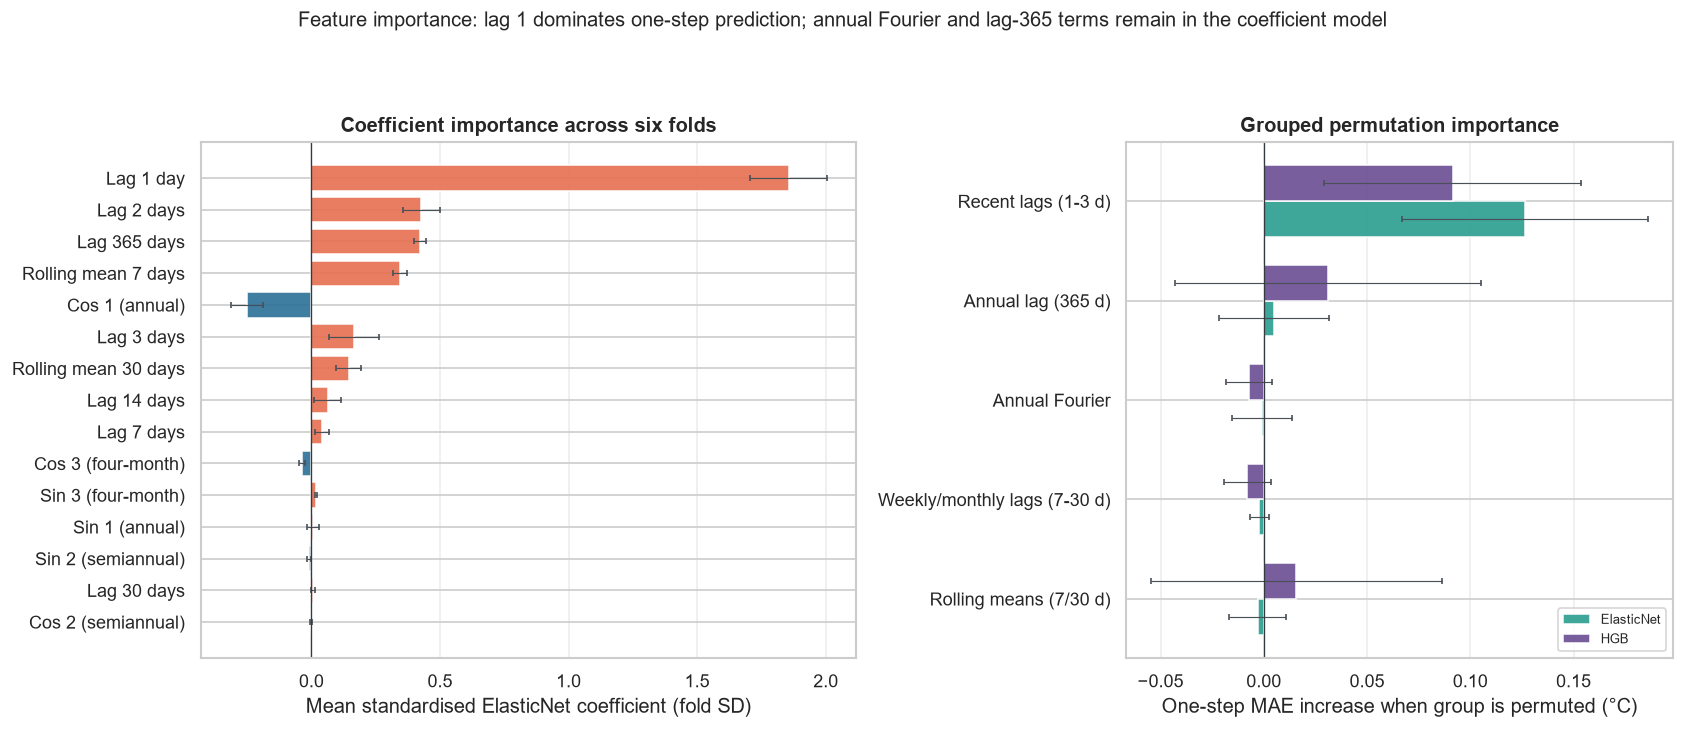

fig_24_feature_importance.png


In [24]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14.2, 6.0),
    gridspec_kw={"width_ratios": [1.2, 1.0]},
)

ax = axes[0]
coef_plot = coef_summary.sort_values("mean_abs_coef", ascending=True)
coef_positions = np.arange(len(coef_plot))
coef_colors = ["#2A6F97" if value < 0 else "#E76F51" for value in coef_plot["mean_coef"]]
ax.barh(
    coef_positions,
    coef_plot["mean_coef"],
    color=coef_colors,
    alpha=0.9,
    xerr=coef_plot["sd_coef"],
    capsize=2,
    error_kw={"elinewidth": 0.7, "ecolor": "#495057"},
)
ax.axvline(0, color="#343A40", linewidth=0.8)
ax.set_yticks(
    coef_positions,
    [FEATURE_LABELS.get(feature, feature) for feature in coef_plot["feature"]],
)
ax.set_xlabel("Mean standardised ElasticNet coefficient (fold SD)")
ax.set_title("Coefficient importance across six folds")
ax.grid(axis="x", alpha=0.35)

ax = axes[1]
group_order = (
    group_summary.loc[group_summary["model"].eq("ElasticNet")]
    .sort_values("mean_importance", ascending=True)["group"]
    .tolist()
)
bar_width = 0.36
for index, (model_label, color) in enumerate(
    [("ElasticNet", "#2A9D8F"), ("HGB", "#6A4C93")]
):
    subset = (
        group_summary.loc[group_summary["model"].eq(model_label)]
        .set_index("group")
        .reindex(group_order)
    )
    positions = np.arange(len(group_order)) + (index - 0.5) * bar_width
    ax.barh(
        positions,
        subset["mean_importance"],
        height=bar_width,
        color=color,
        alpha=0.9,
        xerr=subset["sd_importance"],
        capsize=2,
        error_kw={"elinewidth": 0.7, "ecolor": "#495057"},
        label=model_label,
    )
ax.axvline(0, color="#343A40", linewidth=0.8)
ax.set_yticks(np.arange(len(group_order)), group_order)
ax.set_xlabel("One-step MAE increase when group is permuted (°C)")
ax.set_title("Grouped permutation importance")
ax.grid(axis="x", alpha=0.35)
ax.legend(fontsize=8, frameon=True, loc="lower right")

fig.suptitle(
    "Feature importance: lag 1 dominates one-step prediction; annual Fourier and lag-365 terms remain in the coefficient model",
    fontsize=11.8,
    y=1.01,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
path = save_figure(fig, "fig_24_feature_importance.png")
plt.show()
print(path.name)

### 5.4 Phase F findings

- **Climate zones separate strongly.** Tropical cities have the warmest mean
  temperature and the smallest seasonal amplitude; temperate and high-latitude
  cities have much larger amplitudes. Absolute latitude is negatively
  associated with city mean temperature and positively associated with
  seasonal amplitude. The zone differences are descriptive, not a climate
  trend.
- **Regional differences are real but unevenly sampled.** Asia and Africa
  contribute the largest number of core cities; Europe is cooler on average;
  the Pacific and Indian Ocean groups are small. The timezone-region proxy
  should not be read as an official continent comparison.
- **Air quality has a large level shift in September 2024.** The median
  city-level PM2.5 ratio versus August 2024 is about 2.9, and most cities more
  than double. The same September comparison in 2025 and 2026 is close to 1.
  That pattern is more consistent with a source/level change than with a
  recurring seasonal cycle; it is a data-quality caveat, not a causal claim.
- **Local PM2.5/weather associations are heterogeneous.** Precipitation, cloud,
  and wind have negative median within-city correlations with PM2.5, while
  pressure is positive. But the signs are not universal across cities, so the
  result is a description of this panel rather than a general physical law.
- **Air-quality units remain unknown.** No regulatory threshold or health
  interpretation is made.
- **Feature importance is method-dependent.** Standardised coefficients retain
  lag-1, lag-2, lag-365, the 7-day mean, and the annual cosine as the largest
  terms. One-step permutation importance is dominated by lag-1 for both
  models; grouped permutation confirms that recent lags matter most in that
  one-step view. The small or negative importances of Fourier terms do not
  contradict the recursive backtest: one-step lag-1 already carries much of the
  same information, and the recursive forecast replaces lag-1 with its own
  prediction.

The detailed tables above and the generated Phase F summary are the source of
the exact values.

In [25]:
zone_md = zone_table.rename(
    columns={
        "climate_zone": "Climate zone",
        "n_cities": "Cities",
        "city_days": "City-days",
        "mean_temp_c": "Mean temp (°C)",
        "median_city_temp_c": "Median city temp (°C)",
        "seasonal_amplitude_median_c": "Median seasonal amplitude (°C)",
        "mean_humidity_pct": "Mean humidity (%)",
        "mean_uv_index": "Mean UV index",
        "mean_wind_kph": "Mean wind (kph)",
        "median_city_pm25": "Median city PM2.5",
        "pm25_q25": "PM2.5 Q1",
        "pm25_q75": "PM2.5 Q3",
    }
)
region_md = region_table.rename(
    columns={
        "region": "Region",
        "n_cities": "Cities",
        "city_days": "City-days",
        "mean_temp_c": "Mean temp (°C)",
        "seasonal_amplitude_median_c": "Median seasonal amplitude (°C)",
        "mean_humidity_pct": "Mean humidity (%)",
        "median_city_pm25": "Median city PM2.5",
    }
)
pollutant_md = pollutant_table.rename(
    columns={
        "pollutant": "Pollutant",
        "units": "Units",
        "n": "Rows",
        "missing": "Missing",
        "median": "Median",
        "mean": "Mean",
        "p95": "P95",
        "p99": "P99",
        "max": "Max",
    }
)
step_md = pm25_step_table.rename(
    columns={
        "month": "Month",
        "previous_month": "Previous month",
        "n_cities": "Cities",
        "median_ratio": "Median city ratio",
        "share_gt_1_5": "Share ratio >1.5",
        "share_gt_2": "Share ratio >2",
    }
)
corr_md = pm25_corr_summary.assign(
    variable=lambda frame: frame["variable"].map(SHORT_LABELS)
).rename(
    columns={
        "variable": "Weather variable",
        "n_cities": "Cities",
        "median_r": "Median rho",
        "q25_r": "Q1 rho",
        "q75_r": "Q3 rho",
        "share_negative": "Share negative",
        "share_positive": "Share positive",
        "share_significant_negative": "Share significant negative",
        "share_significant_positive": "Share significant positive",
    }
)
top_pm_md = top_pm[
    ["country", "city", "climate_zone", "region", "median_pm25", "p95_pm25"]
].rename(
    columns={
        "country": "Country",
        "city": "City",
        "climate_zone": "Climate zone",
        "region": "Region",
        "median_pm25": "Median PM2.5",
        "p95_pm25": "P95 PM2.5",
    }
)
coef_md = coef_summary.head(10).assign(
    feature=lambda frame: frame["feature"].map(FEATURE_LABELS)
).rename(
    columns={
        "feature": "Feature",
        "mean_coef": "Mean coefficient",
        "sd_coef": "Fold SD",
        "mean_abs_coef": "Mean absolute coefficient",
        "nonzero_share": "Non-zero share",
    }
)
ind_enet_md = importance_summary["elastic_net"].head(8).assign(
    feature=lambda frame: frame["feature"].map(FEATURE_LABELS)
).rename(
    columns={
        "feature": "Feature",
        "mean_importance": "Mean MAE increase (°C)",
        "sd_importance": "Fold SD",
        "n_folds": "Folds",
        "mean_within_fold_sd": "Mean within-fold SD",
    }
)
ind_hgb_md = importance_summary["hist_gradient_boosting"].head(8).assign(
    feature=lambda frame: frame["feature"].map(FEATURE_LABELS)
).rename(
    columns={
        "feature": "Feature",
        "mean_importance": "Mean MAE increase (°C)",
        "sd_importance": "Fold SD",
        "n_folds": "Folds",
        "mean_within_fold_sd": "Mean within-fold SD",
    }
)
group_md = group_summary.rename(
    columns={
        "group": "Feature group",
        "mean_importance": "Mean MAE increase (°C)",
        "sd_importance": "Fold SD",
        "n_folds": "Folds",
        "mean_within_fold_sd": "Mean within-fold SD",
        "model": "Model",
    }
)

corr_lookup = pm25_corr_summary.set_index("variable")
wind_row = corr_lookup.loc["wind_kph"]
precip_row = corr_lookup.loc["precip_mm"]
cloud_row = corr_lookup.loc["cloud"]
pressure_row = corr_lookup.loc["pressure_mb"]
temperature_row = corr_lookup.loc["temperature_celsius"]

top_coef = coef_summary.iloc[0]
second_coef = coef_summary.iloc[1]
third_coef = coef_summary.iloc[2]
fourth_coef = coef_summary.iloc[3]
top_enet = importance_summary["elastic_net"].iloc[0]
top_hgb = importance_summary["hist_gradient_boosting"].iloc[0]
group_lookup = group_summary.set_index(["model", "group"])
recent_enet = group_lookup.loc[("ElasticNet", "Recent lags (1-3 d)")]
annual_lag_enet = group_lookup.loc[("ElasticNet", "Annual lag (365 d)")]
fourier_enet = group_lookup.loc[("ElasticNet", "Annual Fourier")]
recent_hgb = group_lookup.loc[("HGB", "Recent lags (1-3 d)")]
annual_lag_hgb = group_lookup.loc[("HGB", "Annual lag (365 d)")]
fourier_hgb = group_lookup.loc[("HGB", "Annual Fourier")]

report_path = REPORT_DIR / "advanced_summary.md"
base_text = report_path.read_text(encoding="utf-8")
base_text = base_text.split("<!-- PHASE F START -->")[0].rstrip()
base_text = base_text.split("\n## Phase E checkpoint")[0].rstrip()
base_text = base_text.replace(
    "# Phase E — Advanced anomaly detection and model comparison",
    "# Phase E–F — Advanced analysis: anomalies, models, climate, air quality, and maps",
)
base_text = base_text.replace(
    """**Status:** Complete for review. Phase E only. Climate/region analysis,
air-quality analysis, feature importance, and maps remain Phase F and are not
claimed here.""",
    """**Status:** Complete for review through Phase F. Phase E covers anomaly
detection and model comparison; Phase F adds climate/region, air-quality,
feature-importance, and map analysis.""",
)
base_text = base_text.replace(
    """- Phase E does not include the final report, climate-region analysis,
  air-quality analysis, feature importance with two methods, or maps. Those are
  Phase F/G work.""",
    """- Phase E did not include climate-region analysis, air-quality analysis,
  feature importance with two methods, or maps. Phase F adds those analyses;
  the final report and demo script remain Phase G work.""",
)

phase_f_text = f"""<!-- PHASE F START -->
## Phase F — Climate, region, air quality, feature importance, and maps

**Status:** complete for review. This section is descriptive; no new forecast
metric is claimed. The Phase E anomaly and model-comparison results above are
unchanged.

### Scope and derived groupings

- **Panel:** {len(city_summary)} core cities and {len(core):,} city-day rows;
  {int(city_summary['n_days'].sum()):,} city-days have a temperature value.
- **Climate zone:** absolute-latitude bands (Tropical <23.5°, Subtropical
  23.5–<35°, Temperate 35–<50°, High-latitude ≥50°). This is a transparent
  proxy, not an official Köppen classification.
- **Region:** first component of the IANA timezone string. It is a descriptive
  proxy, not an official continent mapping.
- **Air quality:** all six pollutant variables are in **dataset units** because
  the source does not document concentration units. No regulatory or health
  threshold is applied.
- **Maps:** the public-domain Natural Earth 1:110m land layer is a backdrop
  only; all plotted values come from the weather panel.
- **Feature importance:** standardised ElasticNet coefficients plus
  permutation importance on one-step-ahead test rows. The latter is not the
  recursive 30-day backtest.

The 2026-08-17 temperature event remains in the panel. Its effect on
multi-year city means is negligible, but it is not removed.

### Climate and regional analysis

{markdown_table(zone_md, digits=2)}

The tropical band contains **{int(zone_table.loc[zone_table['climate_zone'].eq('Tropical'), 'n_cities'].iloc[0])}**
cities with a mean city temperature of
**{zone_table.loc[zone_table['climate_zone'].eq('Tropical'), 'mean_temp_c'].iloc[0]:.2f} °C**
and a median seasonal amplitude of
**{zone_table.loc[zone_table['climate_zone'].eq('Tropical'), 'seasonal_amplitude_median_c'].iloc[0]:.2f} °C**.
The temperate and high-latitude bands have median amplitudes near
**{zone_table.loc[zone_table['climate_zone'].eq('Temperate'), 'seasonal_amplitude_median_c'].iloc[0]:.1f} °C**
and
**{zone_table.loc[zone_table['climate_zone'].eq('High-latitude'), 'seasonal_amplitude_median_c'].iloc[0]:.1f} °C**,
respectively. The zone temperature difference is significant in a descriptive
Kruskal-Wallis test (H = **{zone_temp_h:.2f}**, p = **{zone_temp_p:.2e}**), but
this is not a causal or trend claim.

Absolute latitude has a negative city-level Spearman association with mean
temperature (**rho = {lat_temp_rho:.3f}**, p = **{lat_temp_p:.2e}**) and a
positive association with seasonal amplitude
(**rho = {lat_amp_rho:.3f}**, p = **{lat_amp_p:.2e}**). The hottest city mean
is **{hottest['city']}, {hottest['country']}** at
**{hottest['mean_temp_c']:.2f} °C**; the coldest is
**{coldest['city']}, {coldest['country']}** at
**{coldest['mean_temp_c']:.2f} °C**. The largest seasonal amplitude is
**{largest_amplitude['city']}, {largest_amplitude['country']}**
(**{largest_amplitude['seasonal_amplitude_c']:.1f} °C**); the smallest is
**{smallest_amplitude['city']}, {smallest_amplitude['country']}**
(**{smallest_amplitude['seasonal_amplitude_c']:.1f} °C**).

{markdown_table(region_md, digits=2)}

The region table is a timezone proxy, and the groups are unevenly sampled:
Asia has {int(region_table.loc[region_table['region'].eq('Asia'), 'n_cities'].iloc[0])}
core cities and Europe has
{int(region_table.loc[region_table['region'].eq('Europe'), 'n_cities'].iloc[0])},
while the Atlantic and Australia groups have one city each. The regional
contrasts should therefore be read as panel descriptions, not population- or
area-weighted continent estimates.

### Air-quality analysis

{markdown_table(pollutant_md, digits=2)}

The **median of the 183 city medians** is
**{city_summary['median_pm25'].median():.2f}** dataset units; the **pooled
city-day median** is
**{pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'median'].iloc[0]:.2f}**.
The pooled 95th percentile is
**{pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'p95'].iloc[0]:.2f}**,
the 99th percentile is
**{pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'p99'].iloc[0]:.2f}**,
and the maximum city-day value is
**{pollutant_table.loc[pollutant_table['pollutant'].eq('PM2.5'), 'max'].iloc[0]:.2f}**.
The distribution is strongly right-skewed; values are not treated as normally
distributed.

{markdown_table(top_pm_md, digits=2)}

The highest city-median values are **{top_pm.iloc[0]['city']}, {top_pm.iloc[0]['country']}**
(**{top_pm.iloc[0]['median_pm25']:.2f}**), **{top_pm.iloc[1]['city']}, {top_pm.iloc[1]['country']}**
(**{top_pm.iloc[1]['median_pm25']:.2f}**), and **{top_pm.iloc[2]['city']}, {top_pm.iloc[2]['country']}**
(**{top_pm.iloc[2]['median_pm25']:.2f}**). The lowest city median is
**{bottom_pm.iloc[0]['city']}, {bottom_pm.iloc[0]['country']}** at
**{bottom_pm.iloc[0]['median_pm25']:.2f}**.

**Level shift:** the September 2024 median city-level PM2.5 ratio versus
August 2024 is **{sep24['median_ratio']:.3f}**, with
**{100 * sep24['share_gt_1_5']:.1f}%** of cities above 1.5x and
**{100 * sep24['share_gt_2']:.1f}%** above 2x. The same September comparison
is **{sep25['median_ratio']:.3f}** in 2025 and **{sep26['median_ratio']:.3f}**
in 2026. This is better treated as a source/level discontinuity than as a
recurring seasonal effect. It is not used to make a causal or regulatory claim.

{markdown_table(step_md, digits=3)}

{markdown_table(corr_md, digits=3)}

Within-city Spearman correlations with PM2.5 are heterogeneous. The most
negative median associations are wind (**rho = {wind_row['median_r']:.3f}**;
**{100 * wind_row['share_significant_negative']:.1f}%** of cities significant
negative), precipitation (**rho = {precip_row['median_r']:.3f}**;
**{100 * precip_row['share_significant_negative']:.1f}%**), and cloud
(**rho = {cloud_row['median_r']:.3f}**;
**{100 * cloud_row['share_significant_negative']:.1f}%**). Pressure has a
positive median association (**rho = {pressure_row['median_r']:.3f}**;
**{100 * pressure_row['share_significant_positive']:.1f}%** significant
positive), and temperature is weaker and less consistent
(**rho = {temperature_row['median_r']:.3f}**). The signs are not universal
across cities, so these are descriptive local associations, not general
physical laws.

### Feature importance

{markdown_table(coef_md, digits=4)}

The largest mean absolute standardised coefficients are
**{FEATURE_LABELS[top_coef['feature']]}** (**{top_coef['mean_coef']:+.3f}**),
**{FEATURE_LABELS[second_coef['feature']]}** (**{second_coef['mean_coef']:+.3f}**),
**{FEATURE_LABELS[third_coef['feature']]}** (**{third_coef['mean_coef']:+.3f}**),
and **{FEATURE_LABELS[fourth_coef['feature']]}**
(**{fourth_coef['mean_coef']:+.3f}**). The annual cosine term is negative and
non-trivial, so the model does use a seasonal shape even though lag-1 is
largest.

**ElasticNet one-step permutation importance:**

{markdown_table(ind_enet_md, digits=4)}

**HistGradientBoosting one-step permutation importance:**

{markdown_table(ind_hgb_md, digits=4)}

**Grouped permutation importance:**

{markdown_table(group_md, digits=4)}

The top one-step permutation result is **{FEATURE_LABELS[top_enet['feature']]}**
for ElasticNet (**{top_enet['mean_importance']:+.4f} °C MAE increase**) and
**{FEATURE_LABELS[top_hgb['feature']]}** for HGB
(**{top_hgb['mean_importance']:+.4f} °C**). Grouped permutation confirms that
recent lags dominate the one-step view: ElasticNet
**{recent_enet['mean_importance']:+.4f} °C**, HGB
**{recent_hgb['mean_importance']:+.4f} °C**. The annual-lag group is smaller
(ElasticNet **{annual_lag_enet['mean_importance']:+.4f} °C**; HGB
**{annual_lag_hgb['mean_importance']:+.4f} °C**), and the annual Fourier group
is close to zero or slightly negative in this one-step design (ElasticNet
**{fourier_enet['mean_importance']:+.4f} °C**; HGB
**{fourier_hgb['mean_importance']:+.4f} °C**). Small negative values mean that permutation slightly improved the test MAE in
this sample; they are consistent with noise and should not be interpreted as
the feature being harmful.

**Interpretation caveat:** one-step permutation importance is not the same as
recursive multi-step importance. In the recursive backtest, lag-1 is replaced
by the model's own previous prediction, so the model must rely more on
seasonality, longer lags, and rolling means. No recursive feature-importance
claim is made here.

### Phase F caveats

- The climate zones are an absolute-latitude proxy; they do not encode
  elevation, continentality, ocean currents, or official Köppen classes.
- The region groups come from timezone strings and are unevenly sampled.
- Air-quality units are undocumented. The values are not compared with any
  regulatory threshold, and no health claim is made.
- The September 2024 PM2.5 level shift affects cross-time comparisons. It is
  documented but not removed or corrected.
- Within-city Spearman correlations are descriptive; p-values are not
  multiple-testing corrected. Signs vary across cities, so a single global
  relationship is not claimed.
- Feature-importance methods can disagree when predictors are correlated.
  Coefficients are model-specific and standardised; permutation importance is
  one-step and model-specific. Neither is a causal effect.
- The maps use an equirectangular projection. Marker size and colour encode
  different quantities in the two map figures, as stated in their titles.

### Phase F figures

- `reports/figures/fig_20_climate_zone_map.png`
- `reports/figures/fig_21_climate_zone_profiles.png`
- `reports/figures/fig_22_pm25_city_map.png`
- `reports/figures/fig_23_air_quality_patterns.png`
- `reports/figures/fig_24_feature_importance.png`

### Phase F checkpoint

Phase F is complete for review. The notebook executed from top to bottom and
wrote this summary from the actual dataframes. Stop here before Phase G: final
report, PDF export, mission statement insertion, README finalisation, and
`DEMO_SCRIPT.md`.
"""

report_path.write_text(base_text + "\n\n" + phase_f_text + "\n", encoding="utf-8")
print(f"Wrote {report_path}")
print(f"Characters: {len(phase_f_text):,}")

Wrote D:\PMA\pma-data-analytics\reports\advanced_summary.md
Characters: 13,014


## Phase F checkpoint

Phase F is complete for review:

- `notebooks/04_advanced.ipynb` executed from top to bottom with Phase E and
  Phase F sections.
- `src/regional.py` contains reusable climate-zone, air-quality, correlation,
  map, and pollutant-summary helpers; `src/advanced.py` adds the two
  feature-importance methods.
- Five Phase F figures are saved in `reports/figures/`.
- `reports/advanced_summary.md` is generated from the executed dataframes and
  includes Phase E plus Phase F.
- No Phase G deliverable (final report, PDF, mission statement, or demo script)
  is claimed yet.